# Regime Detection in Danish Equities with a Hidden Markov Model

**High_Magus_of_Risk**

---

## The question

A model fitted on a calm market does not work in a crisis. That is uncontroversial, and it is usually handled by refitting, or by adding a volatility term, or by ignoring it. The regime-switching answer is different: assume the market occupies one of a small number of unobserved states, each with its own return and volatility characteristics, and infer which state it is in from what can be observed.

This notebook fits such a model to the OMX Copenhagen General Index from March 2013 to December 2024, a window that contains the 2015 China devaluation, the late-2018 selloff, the COVID crash and the 2022 rate shock. It does not contain the global financial crisis: Yahoo Finance's history for this index now begins in 2013, and section 1 explains why I accepted the shorter sample rather than splice in a substitute. The observables are the daily log return and a 21-day realised volatility.

## The part that decides whether any of it is usable

Most regime-detection work shows a chart of regime probabilities over the sample and stops. That chart is almost always produced by the forward-backward algorithm, which conditions on the whole sample, including everything that happened after the date being labelled. It is a description of history and it cannot be traded.

What a decision at time $t$ can use is the filtered probability, conditioned only on data through $t$. `hmmlearn` does not expose it: `predict_proba` returns the smoothed posterior and `predict` returns the Viterbi path, and both use the full sample. So I implement the scaled forward recursion directly, and section 5 compares the two side by side.

The gap between them is the value of hindsight, and it is large: the same allocation rule earns a Sharpe ratio of 1.39 with a 15% maximum drawdown on smoothed probabilities, and 0.84 with a 28% drawdown on filtered ones. Section 5.1 turns it into a number: how many trading days a real-time user sits inside a crisis before the model tells them they are in one, and how much of the drawdown has already happened by then.

## What is here

| Section | Content |
|---|---|
| 1 | Data, feature construction, coverage diagnostics |
| 2 | Stylized facts: fat tails, volatility clustering, parameter instability |
| 3 | Model specification, forward-backward, Baum-Welch |
| 4 | Fitting: state selection by BIC, random restarts, label switching, transition dynamics |
| 5 | Filtered against smoothed probabilities, and detection lag |
| 6 | Out-of-sample: parameters frozen at the end of 2018, filtered forward through 2024 |
| 7 | A regime-conditional allocation, net of costs, lagged, on filtered signals only |
| 8 | Limitations |

Section 7 includes the same rule run on smoothed probabilities as a counterfactual. It cannot be implemented by anyone, and it is included because it is the result that gets published by accident.

## Reproducibility

Prices are read from a frozen CSV snapshot, so the figures in this notebook are the figures the code produces. Fitting uses 25 random restarts at each state count, with the log-likelihood spread across restarts reported so the multimodality of the likelihood surface is visible rather than assumed away.

## 1. Data Collection

The gold standard observable for a Gaussian HMM in the regime-detection literature is the **daily log return** of a broad equity index, optionally augmented with a **realized volatility** proxy (Ang & Bekaert, 2002; Hamilton, 1989; Guidolin & Timmermann, 2007).

**Feature set used:**
| Feature | Symbol | Construction |
|---|---|---|
| Daily log return | $r_t$ | $\ln(P_t / P_{t-1})$ |
| 21-day realized volatility | $\sigma_t^{(21)}$ | Rolling std of $r_t$ over 21 trading days |

**Data source:** Yahoo Finance via `yfinance`

**Universe, Danish financial assets:**
- `^OMXCGI`, OMX Copenhagen General Index (primary benchmark; Yahoo history from March 2013)
- `NOVO-B.CO`, Novo Nordisk B (largest OMXC25 constituent, ~50 % weight)
- `MAERSK-B.CO`, A.P. Møller-Mærsk B
- `VWS.CO`, Vestas Wind Systems
- `DANSKE.CO`, Danske Bank

The sample runs from March 2013 to December 2024 and contains several distinct stress episodes: the 2015 China devaluation, the fourth quarter of 2018, the COVID crash, and the 2022 tightening cycle.

### Why the sample starts in 2013

The original design used 2005 to 2024 so that the global financial crisis and the sovereign debt crisis would both be in sample. When the data was refreshed, Yahoo Finance's history for `^OMXCGI` began in March 2013, and no other Danish index ticker on the same source reached further back. That left three options: accept the shorter window, build a substitute index from the four large caps that do have 2005 history, or source a longer series elsewhere.

I took the first. A four-stock composite would have restored 2008, but those four names carry idiosyncratic shocks large enough to look like market regimes to the model, Vestas in 2011 and Danske Bank's 2018 money-laundering scandal among them, and a regime model that confuses a single-name scandal for a market state is worse than one estimated on a shorter clean index.

The cost is real and worth stating plainly. The crisis state in this notebook is identified mainly from the COVID crash, which lasted weeks rather than the months of 2008 to 2009, so its estimated persistence and duration rest on very few observations. The model has never seen a slow-moving financial crisis, and I would not expect it to recognise one quickly.

### 1.1, Configuration

All experiment-wide constants are defined here in one place: the sample window, the realized-volatility lookback, and the ticker-to-display-name mapping. Centralising these makes it easy to swap the benchmark or extend the universe without touching downstream cells.

In other words, consider this your beginning terminal, where you may alter the input that æater defines the entire sheets analytics

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})

# Sample window
START_DATE  = "2013-03-01"   # Yahoo history for ^OMXCGI begins March 2013
END_DATE    = "2024-12-31"

# Realized-volatility lookback (21 trading days ≈ 1 calendar month — gold standard)
RVOL_WINDOW = 21

# Danish asset universe: Yahoo Finance ticker → clean display name
# ^OMXCGI (OMX Copenhagen General Index) is used as the primary benchmark because
# ^OMXC25 only has Yahoo Finance data from ~2017 onwards; ^OMXCGI reaches
# back to March 2013, which sets the start of the sample.
TICKERS = {
    "^OMXCGI"    : "OMXCGI Index",        # Primary benchmark (Yahoo history from 2013-03)
    "NOVO-B.CO"  : "Novo Nordisk B",       # Largest OMXC25 constituent (~50 % weight)
    "MAERSK-B.CO": "A.P. Møller-Mærsk B",
    "VWS.CO"     : "Vestas Wind Systems",
    "DANSKE.CO"  : "Danske Bank",
}

print("Configuration loaded.")
print(f"  Sample   : {START_DATE} → {END_DATE}")
print(f"  RVOL win : {RVOL_WINDOW} trading days")
print(f"  Tickers  : {list(TICKERS.values())}")

Configuration loaded.
  Sample   : 2013-03-01 → 2024-12-31
  RVOL win : 21 trading days
  Tickers  : ['OMXCGI Index', 'Novo Nordisk B', 'A.P. Møller-Mærsk B', 'Vestas Wind Systems', 'Danske Bank']


### 1.2, Download Adjusted Close Prices

Daily **adjusted close** prices are read from a frozen CSV snapshot where one is present, and fetched from Yahoo Finance otherwise. Freezing the sample means the figures committed alongside this notebook and the code that produced them cannot drift apart. Adjusted prices matter because they account for dividends and stock splits, ensuring that the return series reflects true economic gains rather than mechanical price discontinuities.

> **Note on benchmark choice:** `^OMXCGI` (OMX Copenhagen General Index) is used as the primary benchmark rather than the more commonly cited `^OMXC25`. Yahoo Finance only carries `^OMXC25` data from roughly 2017 onwards. `^OMXCGI` is a broader index and reaches back to March 2013 on the same source, which is what sets the start of the sample.

A **coverage diagnostic** prints the first valid date for every series and flags any that begin materially after `START_DATE`. A silent gap here would truncate the sample downstream, once rows with a missing benchmark are dropped, without anything in the output indicating that it had happened.

In [2]:
import os

# Prefer the frozen CSV snapshot over a live download. Freezing the sample is
# what makes the figures in this notebook reproducible: if the data is
# re-downloaded on every execution, the charts committed alongside the code and
# the code itself drift apart with nothing in the output to indicate it.
SNAPSHOT = os.path.join("data_cache", "prices_daily.csv")

if os.path.exists(SNAPSHOT):
    raw = pd.read_csv(SNAPSHOT, index_col=0, parse_dates=True)
    raw = raw.loc[START_DATE:END_DATE]
    print(f"Loaded frozen snapshot: {SNAPSHOT}")
else:
    print("No snapshot found, downloading adjusted close prices from Yahoo Finance.")
    raw = yf.download(
        tickers     = list(TICKERS.keys()),
        start       = START_DATE,
        end         = END_DATE,
        auto_adjust = True,
        progress    = False,
    )["Close"]
    raw.columns = [TICKERS[t] for t in raw.columns]

print(f"  Shape  : {raw.shape}")
print(f"  Period : {raw.index[0].date()} to {raw.index[-1].date()}")

# Coverage diagnostic. A series that begins materially after START_DATE will
# silently truncate the sample downstream, once rows with a missing benchmark
# are dropped, so the gap is flagged here rather than discovered later.
print("\n  Data coverage (first valid date per series):")
first_valid = raw.apply(lambda s: s.first_valid_index())
for name, date in first_valid.items():
    gap_days = (date - pd.Timestamp(START_DATE)).days
    flag = f"   GAP: starts {gap_days} days after START_DATE" if gap_days > 5 else ""
    print(f"    {name:<30} {str(date.date())}{flag}")

raw.tail(3)

Loaded frozen snapshot: data_cache/prices_daily.csv
  Shape  : (2976, 5)
  Period : 2013-03-01 to 2024-12-30

  Data coverage (first valid date per series):
    OMXCGI Index                   2013-03-05
    Novo Nordisk B                 2013-03-01
    A.P. Moller-Maersk B           2013-03-01
    Vestas Wind Systems            2013-03-01
    Danske Bank                    2013-03-01


,OMXCGI Index,Novo Nordisk B,A.P. Moller-Maersk B,Vestas Wind Systems,Danske Bank
Date,,,,,
2024-12-23,2924.689941,577.751831,10480.093750,97.665642,171.225494
2024-12-27,2974.909912,590.093872,10656.972656,97.843826,175.934204
2024-12-30,2934.550049,579.236633,10528.735352,97.091484,174.393173


### 1.3, Compute Daily Log Returns

Log returns $r_t = \ln(P_t / P_{t-1})$ are preferred over simple returns for three reasons relevant to HMMs:
1. **Time-additivity**: multi-period returns are sums of single-period log returns, consistent with continuous-time finance.
2. **Approximate normality**: the Gaussian emission assumption of a standard HMM is better satisfied by log returns than by simple returns.
3. **Stationarity**: prices are I(1); log returns are stationary, which is required for the ergodic properties of the Baum-Welch estimator.

In [3]:
log_returns = np.log(raw / raw.shift(1)).dropna(how="all")

print(f"Log returns shape: {log_returns.shape}")
print(f"\nDescriptive statistics (daily log returns):")
log_returns.describe().round(5)

Log returns shape: (2973, 5)

Descriptive statistics (daily log returns):


,OMXCGI Index,Novo Nordisk B,A.P. Moller-Maersk B,Vestas Wind Systems,Danske Bank
count,2893.00000,2931.00000,2931.00000,2931.00000,2931.00000
mean,0.00052,0.00063,0.00029,0.00081,0.00027
std,0.01085,0.01735,0.02247,0.02618,0.01716
min,-0.11172,-0.23220,-0.18552,-0.21230,-0.12046
25%,-0.00522,-0.00826,-0.01231,-0.01254,-0.00856
50%,0.00087,0.00050,0.00064,0.00051,0.00049
75%,0.00680,0.00980,0.01297,0.01371,0.00911
max,0.07011,0.15924,0.11660,0.15860,0.11380


### 1.4, Handle Missing Data

Two sources of missingness arise in practice:
- **Exchange holidays**: Nasdaq Copenhagen is closed on Danish public holidays that are not global holidays, producing NaN gaps of 1–3 days in the index but not in globally traded names.
- **Listing gaps**: individual stocks may have isolated NaNs around corporate events (halts, delistings, index rebalances).

**Strategy:** forward-fill gaps of up to 3 consecutive trading days (carries the last valid price, implying a zero return, which is the conservative assumption). Any row where the primary benchmark (`OMXCGI Index`) is still missing after filling is dropped entirely, as the index is the HMM's main observable.

In [4]:
log_returns = log_returns.ffill(limit=3)
log_returns = log_returns.dropna(subset=["OMXCGI Index"])

print(f"Clean shape : {log_returns.shape}  ({log_returns.index[0].date()} → {log_returns.index[-1].date()})")
print(f"\nRemaining NaNs per series:")
print(log_returns.isna().sum().to_string())

Clean shape : (2971, 5)  (2013-03-06 → 2024-12-30)

Remaining NaNs per series:
OMXCGI Index            0
Novo Nordisk B          0
A.P. Moller-Maersk B    0
Vestas Wind Systems     0
Danske Bank             0


### 1.5, Realized Volatility

A 21-day rolling standard deviation of log returns, annualised by $\times\sqrt{252}$, serves as a second observable for the HMM:

$$\sigma_t^{(21)} = \sqrt{\frac{252}{21} \sum_{i=0}^{20} \left(r_{t-i} - \bar{r}\right)^2}$$

Including realized volatility alongside returns lets the HMM distinguish between regimes that share similar mean returns but differ in variance, a well-documented feature of financial markets (e.g. a tranquil bull market vs. a recovering post-crash market can both have positive drift but very different volatility). This is the setup advocated by Ang & Bekaert (2002) and Guidolin & Timmermann (2007).

In [5]:
rvol = log_returns.rolling(RVOL_WINDOW).std() * np.sqrt(252)

benchmark_rvol = rvol["OMXCGI Index"].rename("realized_vol_21d")

print(f"Realized volatility (annualised, {RVOL_WINDOW}-day window):")
benchmark_rvol.describe().round(4)

Realized volatility (annualised, 21-day window):


count    2951.0000
mean        0.1568
std         0.0620
min         0.0613
25%         0.1136
50%         0.1429
75%         0.1844
max         0.4992
Name: realized_vol_21d, dtype: float64

### 1.6, Assemble the HMM Feature Matrix

The final feature matrix `features` is a $T \times 2$ array passed directly to the HMM at fitting time. Each row $t$ is the observation vector $\mathbf{x}_t = [r_t,\ \sigma_t^{(21)}]^\top$. Rows with NaN (the first 20 days lost to the RVOL warm-up period) are dropped here so the matrix is complete.

In [6]:
benchmark_ret = log_returns["OMXCGI Index"].rename("log_return")

features = pd.concat([benchmark_ret, benchmark_rvol], axis=1).dropna()

print(f"HMM feature matrix  : {features.shape[0]} observations × {features.shape[1]} features")
print(f"Period              : {features.index[0].date()} → {features.index[-1].date()}")
print(f"\nFeature summary:")
features.describe().round(5)

HMM feature matrix  : 2951 observations × 2 features
Period              : 2013-04-08 → 2024-12-30

Feature summary:


,log_return,realized_vol_21d
count,2951.00000,2951.00000
mean,0.00056,0.15681
std,0.01080,0.06203
min,-0.11172,0.06134
25%,-0.00518,0.11356
50%,0.00089,0.14292
75%,0.00687,0.18445
max,0.07011,0.49923


### 1.7, Overview Plot

A three-panel chart provides a visual sanity-check before modelling:
- **Top:** Rebased price index (first observation = 100) to show the long-run price path.
- **Middle:** Daily log returns to inspect the return series for volatility clustering and outliers.
- **Bottom:** 21-day annualised realized volatility to confirm that stress periods are captured.

Grey bands mark four well-known crisis or stress episodes to help anchor what regime changes *should* look like in the data.

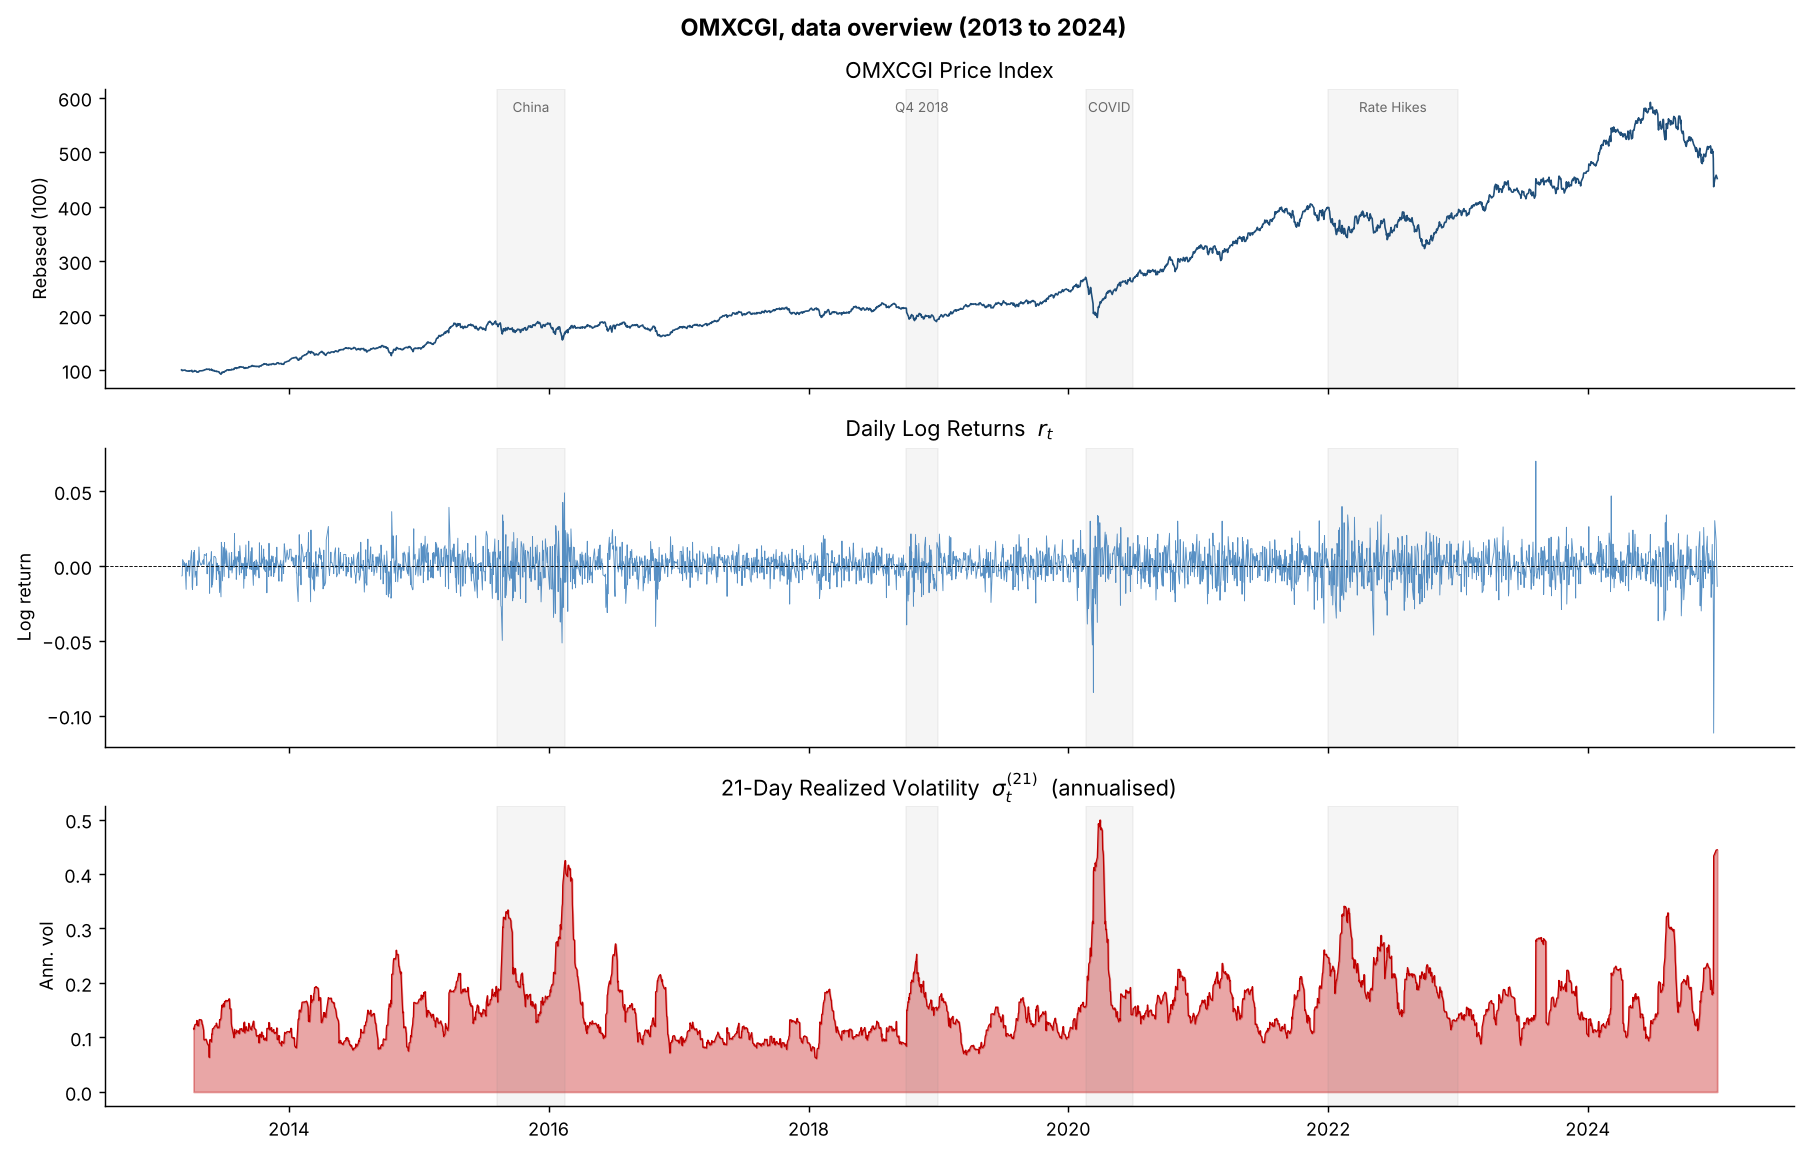

Data collection complete. `features` is ready for HMM fitting.


In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig.suptitle(f"OMXCGI, data overview ({features.index[0].year} to {features.index[-1].year})", fontsize=13, fontweight="bold")

# Panel 1: Rebased price index
# Drop NaNs before rebasing so iloc[0] is the first valid price, not NaN
omxcgi_price = raw["OMXCGI Index"].dropna()
price_idx = omxcgi_price / omxcgi_price.iloc[0] * 100
axes[0].plot(price_idx.index, price_idx.values, color="#1f4e79", linewidth=0.9)
axes[0].set_ylabel("Rebased (100)")
axes[0].set_title("OMXCGI Price Index")

# Panel 2: Daily log returns
axes[1].plot(benchmark_ret.index, benchmark_ret.values, color="#2e75b6", linewidth=0.5, alpha=0.8)
axes[1].axhline(0, color="black", linewidth=0.5, linestyle="--")
axes[1].set_ylabel("Log return")
axes[1].set_title("Daily Log Returns  $r_t$")

# Panel 3: Realized volatility
axes[2].fill_between(benchmark_rvol.index, benchmark_rvol.values, color="#c00000", alpha=0.35)
axes[2].plot(benchmark_rvol.index, benchmark_rvol.values, color="#c00000", linewidth=0.7)
axes[2].set_ylabel("Ann. vol")
axes[2].set_title(f"21-Day Realized Volatility  $\\sigma_t^{{(21)}}$  (annualised)")

# Shade known stress / crisis episodes
crises = [
    ("2015-08-10", "2016-02-15", "China"),
    ("2018-10-01", "2018-12-31", "Q4 2018"),
    ("2020-02-20", "2020-06-30", "COVID"),
    ("2022-01-01", "2022-12-31", "Rate Hikes"),
]
for ax in axes:
    for start, end, label in crises:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.08, color="grey")

# Label crises on top panel only
for start, end, label in crises:
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
    axes[0].text(mid, price_idx.max() * 0.97, label, ha="center", fontsize=7.5, color="dimgrey")

axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Data collection complete. `features` is ready for HMM fitting.")

## 2. Exploratory Analysis

Before fitting an HMM I document the empirical properties, the **stylized facts**, of the return series. These properties simultaneously validate the data and motivate the modelling choice: a standard single-Gaussian model cannot explain leptokurtosis or volatility clustering, but a $K$-state Gaussian HMM, whose unconditional distribution is a finite mixture of Gaussians, can.

The analysis proceeds in six steps:

| Step | Content |
|------|---------|
| 2.1 | Descriptive statistics & distributional moments |
| 2.2 | Return distribution & fat tails |
| 2.3 | Normal Q–Q plot |
| 2.4 | Autocorrelation structure (returns & squared returns) |
| 2.5 | Rolling statistics & non-stationarity |
| 2.6 | Cross-asset correlation dynamics |

### 2.1, Descriptive Statistics & Distributional Moments

The first four **distributional moments** of the return series carry direct financial and econometric meaning:

| Moment | Statistic | Financial interpretation |
|---|---|---|
| 1st (mean) | $\bar{r} \times 252$ | Annualised expected drift |
| 2nd (std) | $\hat{\sigma} \times \sqrt{252}$ | Annualised volatility (risk) |
| 3rd (skewness) | $S = \frac{1}{T}\sum \left(\frac{r_t - \bar{r}}{\hat{\sigma}}\right)^3$ | $S < 0$: crash asymmetry; downside tail heavier than upside |
| 4th (excess kurtosis) | $\kappa - 3 = \frac{1}{T}\sum \left(\frac{r_t - \bar{r}}{\hat{\sigma}}\right)^4 - 3$ | $\kappa - 3 > 0$: leptokurtosis; fat tails relative to Normal |

The **Jarque-Bera test** combines skewness and excess kurtosis into a single omnibus normality statistic:
$$JB = \frac{T}{6}\left[S^2 + \frac{(\kappa - 3)^2}{4}\right] \sim \chi^2(2) \text{ under } H_0\text{: Normal}$$

A small $p$-value rejects normality and is expected for all equity return series. **Historical Value-at-Risk (VaR)** at 1% and 5% reports the empirical quantile of the daily loss distribution, the loss exceeded on 1 or 5 trading days per 100, respectively.

In [8]:
from scipy import stats

def return_moments(df):
    rows = {}
    for col in df.columns:
        s = df[col].dropna()
        jb_stat, jb_p = stats.jarque_bera(s)
        rows[col] = {
            "Ann. Mean (%)":  round(s.mean() * 252 * 100, 2),
            "Ann. Vol (%)":   round(s.std()  * np.sqrt(252) * 100, 2),
            "Skewness":       round(s.skew(), 3),
            "Exc. Kurtosis":  round(s.kurtosis(), 3),
            "JB Stat":        round(jb_stat, 1),
            "JB p-value":     round(jb_p, 4),
            "VaR 1% (daily)": round(np.percentile(s, 1), 5),
            "VaR 5% (daily)": round(np.percentile(s, 5), 5),
        }
    return pd.DataFrame(rows).T

moments_tbl = return_moments(log_returns.dropna(how="all"))
print("Distributional moments \u2014 all series:")
display(moments_tbl)

jb_pvals   = moments_tbl["JB p-value"]
n_rejected = (jb_pvals < 0.05).sum()
n_total    = len(jb_pvals)
if n_rejected == n_total:
    print(f"\nAll {n_total} series: JB p-value < 0.05 \u2192 normality rejected for every series.")
else:
    print(f"\n{n_rejected}/{n_total} series reject normality at the 5% level (JB p-value < 0.05).")
    not_rej = jb_pvals[jb_pvals >= 0.05].index.tolist()
    print(f"  Not rejected: {not_rej}")

Distributional moments — all series:


,Ann. Mean (%),Ann. Vol (%),Skewness,Exc. Kurtosis,JB Stat,JB p-value,VaR 1% (daily),VaR 5% (daily)
OMXCGI Index,13.61,17.11,-0.667,7.062,6369.0,0.0,-0.02862,-0.01674
Novo Nordisk B,15.73,27.44,-1.040,19.081,45442.5,0.0,-0.04124,-0.02397
A.P. Moller-Maersk B,7.67,35.61,-0.338,4.177,2207.0,0.0,-0.05948,-0.03415
Vestas Wind Systems,19.22,41.49,-0.127,5.686,3994.1,0.0,-0.06830,-0.03876
Danske Bank,5.54,27.27,-0.251,4.742,2802.7,0.0,-0.04813,-0.02630



All 5 series: JB p-value < 0.05 → normality rejected for every series.


### 2.2, Return Distribution & Fat Tails

Equity return distributions are empirically **leptokurtic**: the density is more sharply peaked at the centre and has heavier tails than a Normal distribution with the same mean and variance. What matters for HMM modelling is that this unconditional non-normality is **entirely consistent** with a Gaussian HMM:

> A finite mixture of $K$ Normal distributions $\sum_k \pi_k \, \mathcal{N}(\mu_k, \sigma_k^2)$ has unconditional tails that are heavier than any single component, even if each component is perfectly Gaussian.

In the HMM, each state $k$ emits observations from $\mathcal{N}(\mu_k, \sigma_k^2)$. A high-variance *crisis* state naturally generates the fat-tail observations, while a low-variance *calm* state generates the dense central mass. The fat tails are thus a **model prediction**, not a model violation. This is one of the primary reasons the Gaussian HMM is the workhorse model in the regime-detection literature.

Two panels make this concrete: a **linear-scale density** to compare the body, and a **log-scale density** to magnify tail behaviour where the empirical excess is most pronounced.

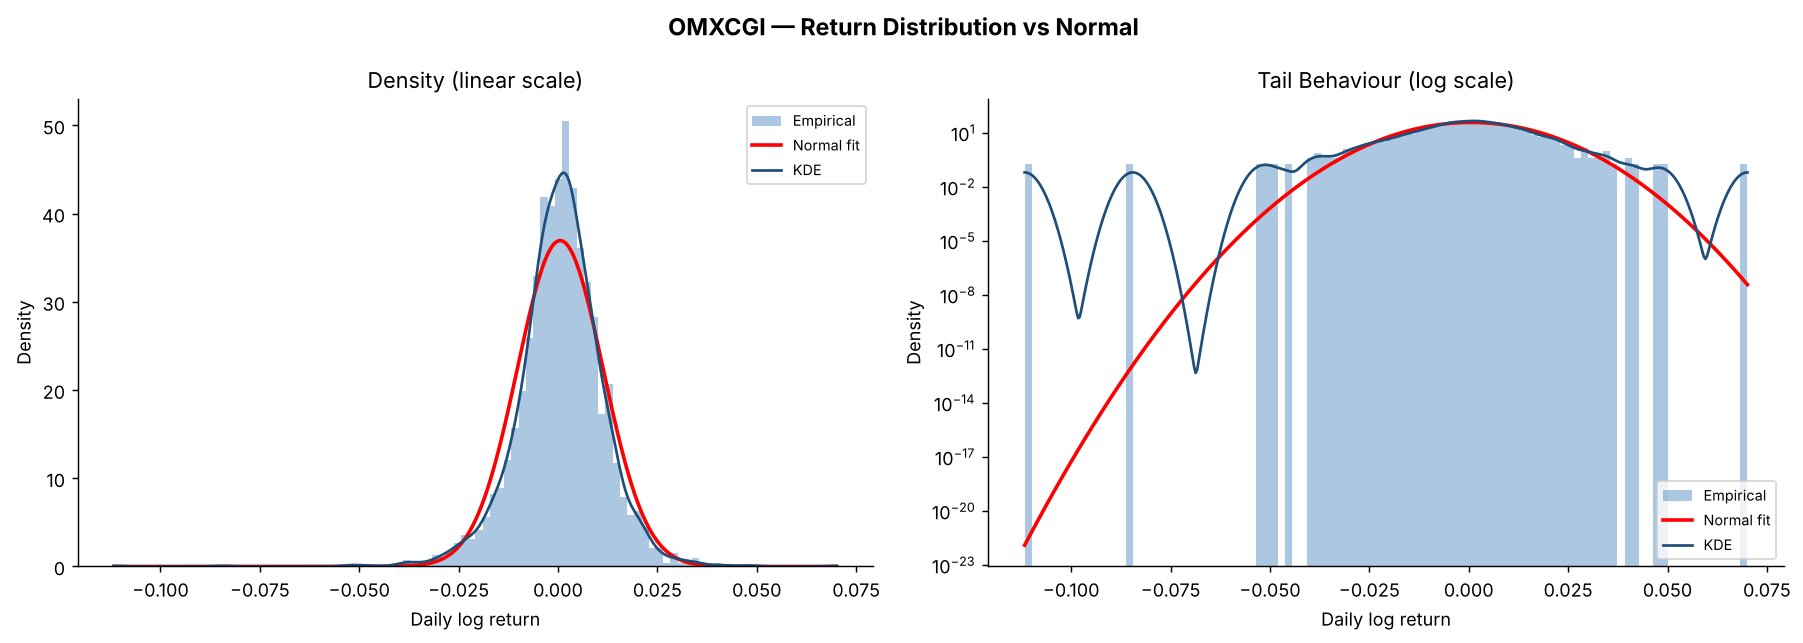

Empirical |r_t| > 3σ  : 1.08%
Normal    |r_t| > 3σ  : 0.27%
Fat-tail excess factor : 4.0×


In [9]:
from scipy.stats import norm, gaussian_kde

ret = features["log_return"]
mu, sigma = ret.mean(), ret.std()
x = np.linspace(ret.min(), ret.max(), 500)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("OMXCGI — Return Distribution vs Normal", fontsize=13, fontweight="bold")

for ax, yscale, title in zip(axes, ["linear", "log"],
                              ["Density (linear scale)", "Tail Behaviour (log scale)"]):
    ax.hist(ret, bins=100, density=True, color="#2e75b6", alpha=0.4, label="Empirical")
    ax.plot(x, norm.pdf(x, mu, sigma), "r-",            linewidth=2,   label="Normal fit")
    ax.plot(x, gaussian_kde(ret)(x),    color="#1f4e79", linewidth=1.5, label="KDE")
    ax.set_yscale(yscale)
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

tail_threshold = 3 * sigma
emp    = (ret.abs() > tail_threshold).mean()
theory = 2 * (1 - norm.cdf(3))
print(f"Empirical |r_t| > 3\u03c3  : {emp*100:.2f}%")
print(f"Normal    |r_t| > 3\u03c3  : {theory*100:.2f}%")
print(f"Fat-tail excess factor : {emp/theory:.1f}\u00d7")

### 2.3, Normal Q–Q Plot

A **Q–Q plot** (quantile–quantile plot) maps the empirical quantiles of the return series against the theoretical quantiles of a standard Normal. If the return distribution were Normal, all points would lie exactly on the 45° reference line.

The characteristic **S-shape** observed in financial return Q–Q plots reveals **leptokurtosis**:
- In the **left tail** (most negative returns), sample quantiles lie *below* the reference line → empirical crashes are more severe than the Normal predicts.
- In the **right tail** (most positive returns), sample quantiles lie *above* the reference line → empirical rallies are larger than the Normal predicts.

This S-shape is precisely the shape of the unconditional distribution generated by a **finite Gaussian mixture**: when the HMM assigns different variances to each regime, the mixture's tails exceed those of any single component. The Q–Q plot thus serves as a visual confirmation that the Gaussian HMM is a well-motivated modelling choice: the fat tails are a *model prediction*, not a model violation.

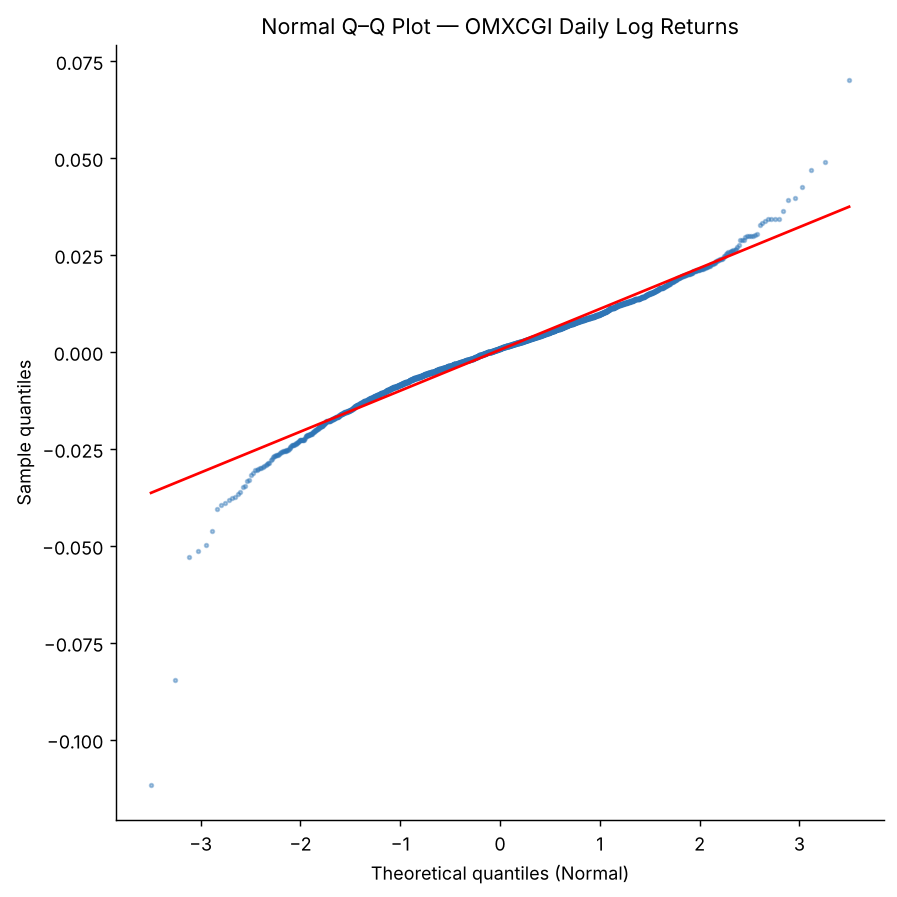

In [10]:
from scipy import stats as sp_stats

fig, ax = plt.subplots(figsize=(7, 7))
sp_stats.probplot(features["log_return"], dist="norm", plot=ax)
ax.get_lines()[0].set(markersize=2, alpha=0.4, color="#2e75b6")
ax.get_lines()[1].set(color="red", linewidth=1.5)
ax.set_title("Normal Q\u2013Q Plot \u2014 OMXCGI Daily Log Returns", fontsize=12)
ax.set_xlabel("Theoretical quantiles (Normal)")
ax.set_ylabel("Sample quantiles")
plt.tight_layout()
plt.show()

### 2.4, Autocorrelation Structure (Returns & Squared Returns)

Two ACF diagnostics are central to justifying the HMM:

**1. Returns $r_t$:**  
Under the Efficient Market Hypothesis (weak form), daily returns should exhibit negligible linear predictability: the ACF of $r_t$ should lie within the ±95% confidence bands at all lags. Significant autocorrelation in $r_t$ would imply a momentum or mean-reversion signal exploitable by a linear filter; the HMM is not designed to capture this.

**2. Squared returns $r_t^2$:**  
Strong, slowly decaying autocorrelation in $r_t^2$ is the empirical signature of **volatility clustering**: large absolute returns tend to follow large absolute returns: *"large changes tend to be followed by large changes"* (Mandelbrot, 1963). This is the ARCH effect (Engle, 1982; Nobel Prize 2003) and is the primary motivation for regime-dependent variance. The HMM's hidden state is, in essence, a **variance-regime indicator**. The **Ljung-Box statistic** formally tests $H_0$: the first $k$ autocorrelations are jointly zero:

$$LB(k) = T(T+2) \sum_{j=1}^k \frac{\hat{\rho}_j^2}{T-j} \sim \chi^2(k) \;\text{ under } H_0.$$

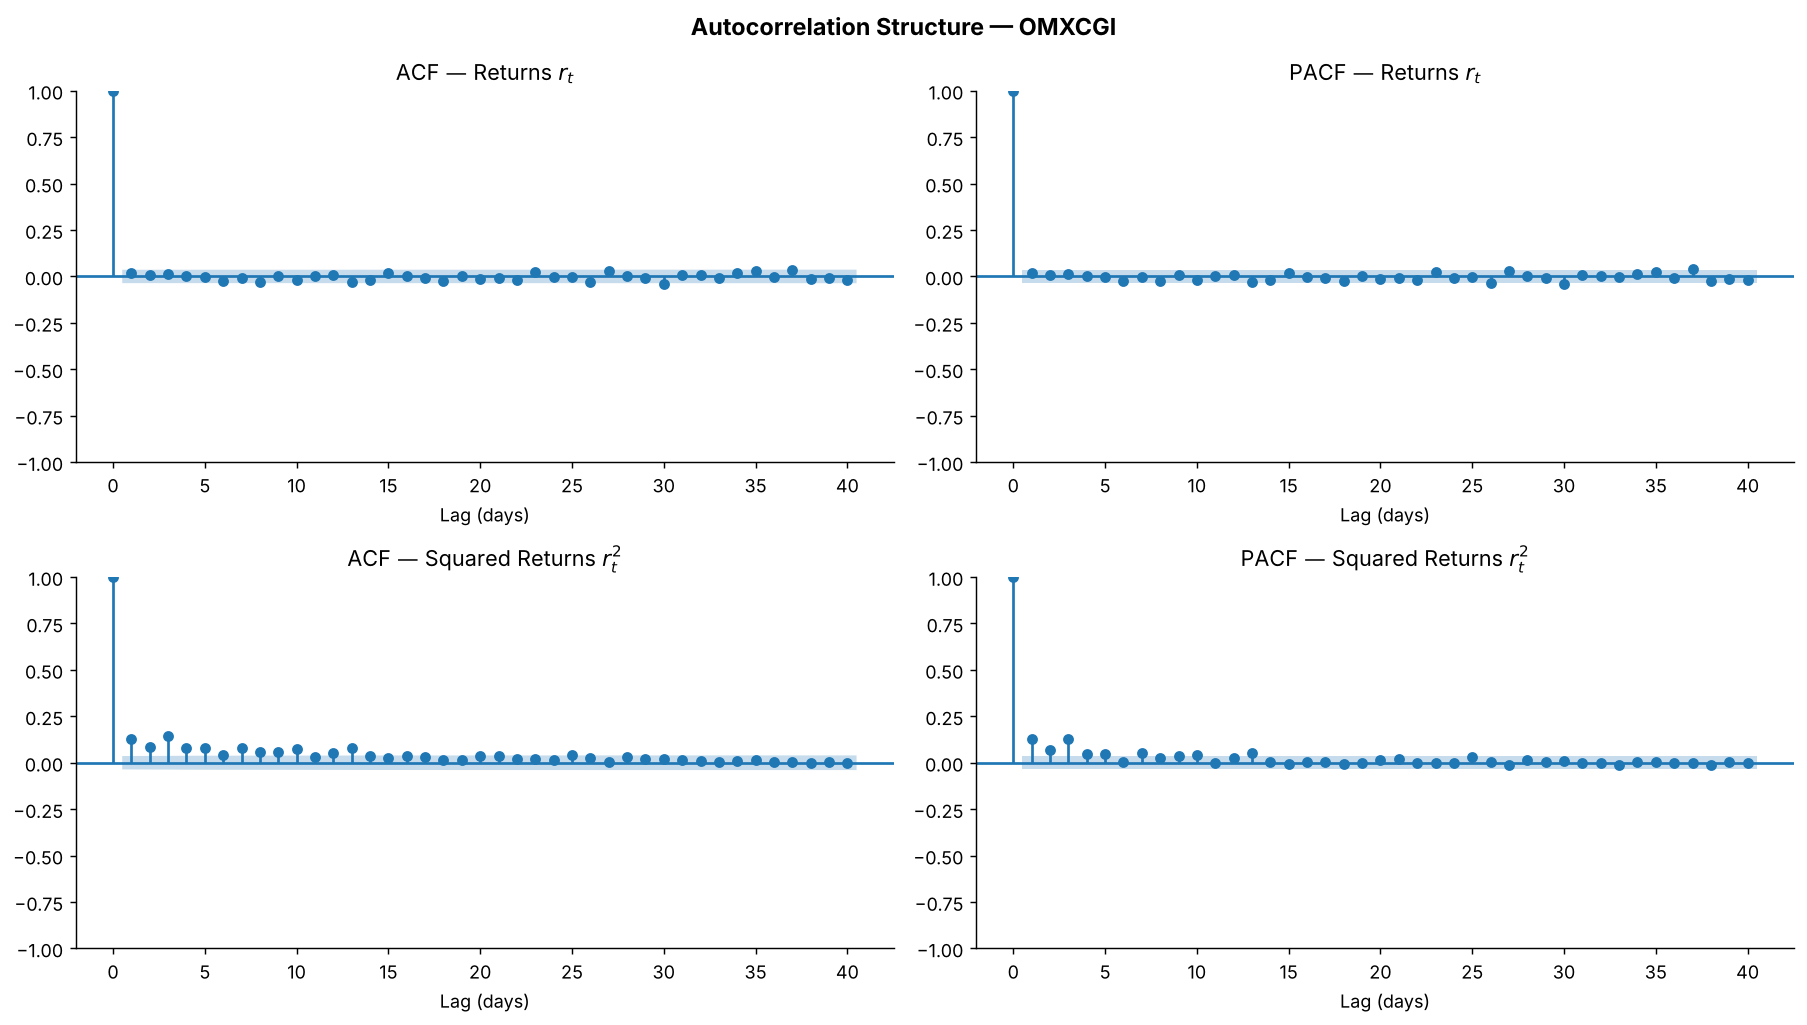

Ljung-Box — Returns r_t  (H₀: no autocorrelation):
    lb_stat  lb_pvalue
10   6.8854     0.7362
20  14.0522     0.8278
40  37.0485     0.6039

Ljung-Box — Squared returns r_t²  (H₀: no autocorrelation):
     lb_stat  lb_pvalue
10  226.4468        0.0
20  275.1179        0.0
40  297.0971        0.0


In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

ret    = features["log_return"]
ret_sq = ret ** 2

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Autocorrelation Structure — OMXCGI", fontsize=13, fontweight="bold")

plot_acf( ret,    lags=40, ax=axes[0,0], title="ACF — Returns $r_t$",            alpha=0.05)
plot_pacf(ret,    lags=40, ax=axes[0,1], title="PACF — Returns $r_t$",           alpha=0.05)
plot_acf( ret_sq, lags=40, ax=axes[1,0], title="ACF — Squared Returns $r_t^2$",  alpha=0.05)
plot_pacf(ret_sq, lags=40, ax=axes[1,1], title="PACF — Squared Returns $r_t^2$", alpha=0.05)

for ax in axes.flat:
    ax.set_xlabel("Lag (days)")

plt.tight_layout()
plt.show()

lb_ret = acorr_ljungbox(ret,    lags=[10, 20, 40], return_df=True)
lb_sq  = acorr_ljungbox(ret_sq, lags=[10, 20, 40], return_df=True)
print("Ljung-Box — Returns r_t  (H\u2080: no autocorrelation):")
print(lb_ret.round(4).to_string())
print("\nLjung-Box — Squared returns r_t\u00b2  (H\u2080: no autocorrelation):")
print(lb_sq.round(4).to_string())

### 2.5, Rolling Statistics & Non-Stationarity

A stationary return process would exhibit rolling estimates of the mean and variance that fluctuate narrowly around fixed values. Empirically, they do not:

- The **rolling mean** alternates between positive and negative territory, driven by multi-month trending and de-trending episodes.
- The **rolling volatility** spikes sharply during stress episodes (e.g. COVID-2020, the 2022 rate-hike cycle) and compresses in tranquil bull-market periods.

This **parameter instability**, the conditional moments $\mu_t$ and $\sigma_t^2$ changing over time, is the direct empirical argument for a regime-switching framework. A single-regime model imposes fixed $(\mu, \sigma^2)$ for the entire sample, blending episodes that are structurally distinct. The HMM relaxes this by allowing each latent state $k$ to have its own $(\mu_k, \sigma_k^2)$, with the Baum-Welch algorithm learning these parameters and the Viterbi algorithm decoding which state is active at each $t$.

Window used: **63 trading days** (≈ one calendar quarter).

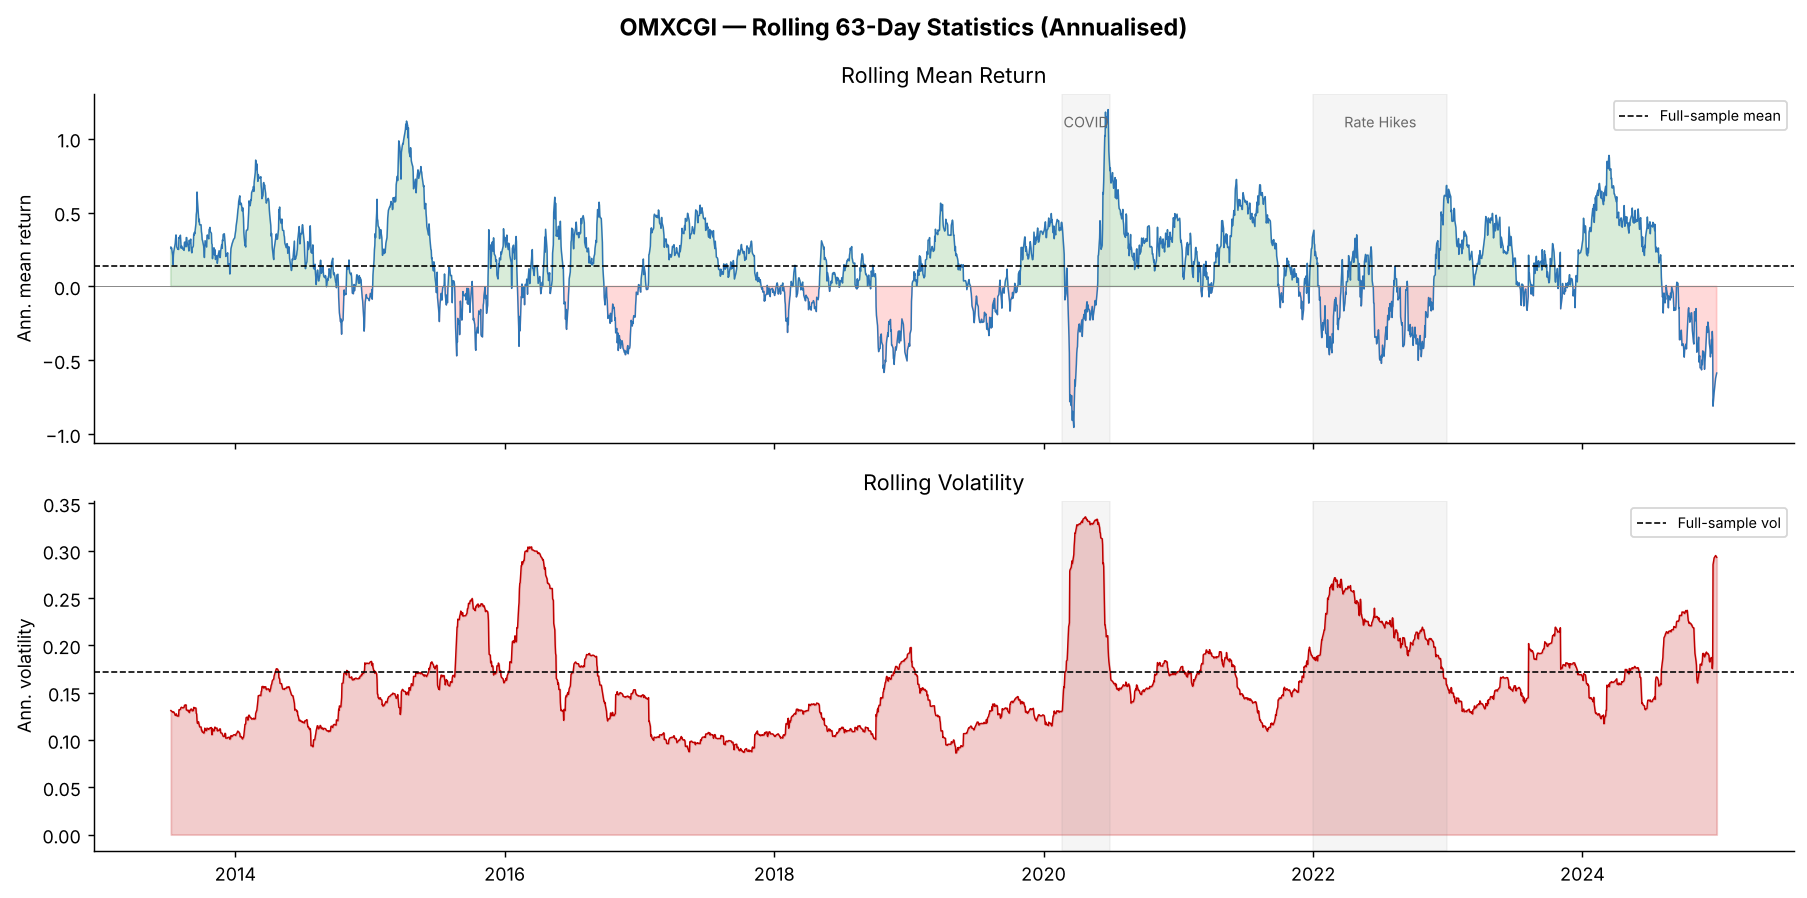

In [12]:
ROLL_WIN = 63  # ~1 quarter of trading days

ret = features["log_return"]
roll_mean = ret.rolling(ROLL_WIN).mean() * 252
roll_vol  = ret.rolling(ROLL_WIN).std()  * np.sqrt(252)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
fig.suptitle(f"OMXCGI — Rolling {ROLL_WIN}-Day Statistics (Annualised)", fontsize=13, fontweight="bold")

axes[0].plot(roll_mean.index, roll_mean.values, color="#2e75b6", linewidth=0.8)
axes[0].axhline(ret.mean()*252, color="black", linewidth=0.9, linestyle="--", label="Full-sample mean")
axes[0].axhline(0, color="grey", linewidth=0.5)
axes[0].fill_between(roll_mean.index, roll_mean.values, 0,
                      where=(roll_mean.values > 0), alpha=0.15, color="green")
axes[0].fill_between(roll_mean.index, roll_mean.values, 0,
                      where=(roll_mean.values < 0), alpha=0.15, color="red")
axes[0].set_ylabel("Ann. mean return")
axes[0].set_title("Rolling Mean Return")
axes[0].legend(fontsize=8)

axes[1].plot(roll_vol.index, roll_vol.values, color="#c00000", linewidth=0.8)
axes[1].axhline(ret.std()*np.sqrt(252), color="black", linewidth=0.9, linestyle="--", label="Full-sample vol")
axes[1].fill_between(roll_vol.index, roll_vol.values, color="#c00000", alpha=0.2)
axes[1].set_ylabel("Ann. volatility")
axes[1].set_title("Rolling Volatility")
axes[1].legend(fontsize=8)

crises = [
    ("2020-02-20", "2020-06-30", "COVID"),
    ("2022-01-01", "2022-12-31", "Rate Hikes"),
]
for ax in axes:
    for start, end, label in crises:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.08, color="grey")
for start, end, label in crises:
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
    axes[0].text(mid, roll_mean.max() * 0.9, label, ha="center", fontsize=8, color="dimgrey")

axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 2.6, Cross-Asset Correlation Dynamics

Pairwise correlations between Danish equities are not constant over time. During stress periods, correlations tend to spike toward unity, a phenomenon known as *correlation breakdown*, as systematic risk dominates idiosyncratic factors and diversification benefits erode precisely when they are most needed.

Two sub-sample heatmaps illustrate this: the **full available sample** vs the **COVID crash** (Feb–Jun 2020), the most acute stress episode within the OMXCGI data window. An elevated average correlation in the crisis period is the expected signature of a high-volatility, high-co-movement regime.

For the bivariate HMM fitted in Section 4, this is informative context: the hidden state identified as "crisis" corresponds to the co-movement regime observed here. A natural extension, beyond the scope of this notebook, is a multivariate HMM where the full covariance matrix $\Sigma_k$ is regime-dependent.

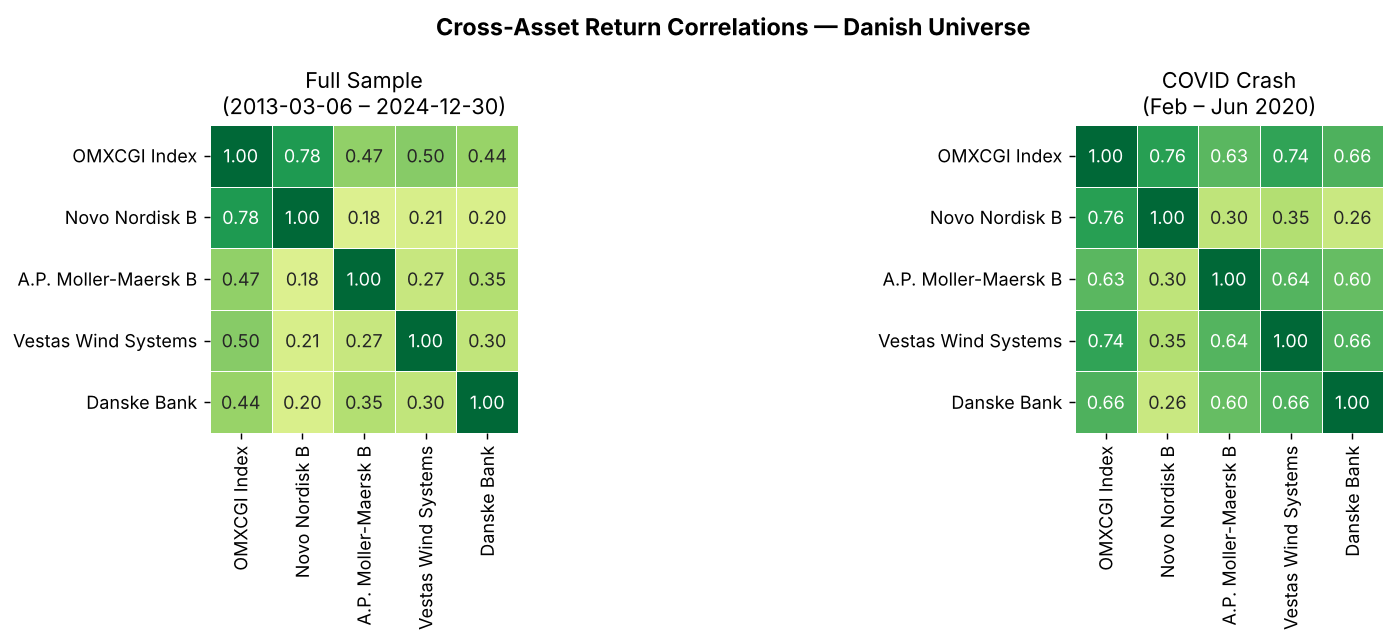


Full-sample average pairwise correlation : 0.37
COVID-crash average pairwise correlation  : 0.561


In [13]:
import seaborn as sns

lr_clean = log_returns.dropna(how="all")

full_corr  = lr_clean.dropna(axis=1, how="all").corr()
covid_corr = lr_clean.loc["2020-02-20":"2020-06-30"].dropna(axis=1, how="all").corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Cross-Asset Return Correlations — Danish Universe", fontsize=13, fontweight="bold")

kw = dict(annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1,
          center=0, square=True, linewidths=0.5, cbar=False)

sns.heatmap(full_corr,  ax=axes[0], **kw)
axes[0].set_title(f"Full Sample\n({lr_clean.index[0].date()} – {lr_clean.index[-1].date()})")

sns.heatmap(covid_corr, ax=axes[1], **kw)
axes[1].set_title("COVID Crash\n(Feb – Jun 2020)")

plt.tight_layout()
plt.show()

print("\nFull-sample average pairwise correlation :",
      round(full_corr.where(np.triu(np.ones_like(full_corr, dtype=bool), k=1)).stack().mean(), 3))
print("COVID-crash average pairwise correlation  :",
      round(covid_corr.where(np.triu(np.ones_like(covid_corr, dtype=bool), k=1)).stack().mean(), 3))

### 2.7, Stylized Facts Summary & HMM Motivation

The six diagnostics above confirm the canonical stylized facts of equity returns. The table below links each finding to its implication for HMM modelling:

| Stylized Fact | Evidence | HMM Implication |
|---|---|---|
| **Leptokurtosis** | Excess kurtosis ≫ 0; fat-tail excess > 3× Normal | Mixture of Gaussians generates unconditional fat tails without requiring non-Normal emissions |
| **Negative skewness** | Skew < 0 for index and most stocks | Asymmetric regime occupancy: bear regimes are shorter but more extreme |
| **Near-zero ACF of $r_t$** | Ljung-Box p-values > 0.05 at most lags | Weak-form efficiency holds; HMM does not require linear autocorrelation in returns |
| **Strong ACF of $r_t^2$** | Ljung-Box p-values ≪ 0.05; slow ACF decay | Volatility clustering → regime-dependent variance $\sigma_k^2$; HMM hidden state is largely a variance indicator |
| **Rolling parameter instability** | $\hat{\mu}_t$ and $\hat{\sigma}_t$ vary widely over time | Single-regime models are misspecified; HMM allows $(\mu_k, \sigma_k^2)$ to differ across states |
| **Correlation breakdown** | Pairwise correlations spike during COVID crash | Regime-dependent co-movement; motivates multivariate HMM extensions |

**Conclusion:** The data satisfies the conditions under which a Gaussian HMM is both identifiable and useful:
1. Returns are approximately conditionally Gaussian within each regime.
2. Variance (not mean) is the primary differentiator between regimes.
3. Regime transitions are persistent enough to be detectable with the Viterbi algorithm.

Section 3 proceeds to fit a $K$-state Gaussian HMM using the Baum-Welch (EM) algorithm and selects $K$ via the Bayesian Information Criterion.

## 3. The model

Section 2 established that Danish equity returns are leptokurtic, that their volatility clusters, and that rolling estimates of both mean and variance wander far enough to make a single-regime description untenable. A Hidden Markov Model is one response to that: instead of one distribution with awkward moments, assume several well-behaved distributions and an unobserved process that switches between them.

### 3.1 Specification

Let $S_t \in \{1, \dots, K\}$ be an unobserved state and $\mathbf{x}_t = [r_t, \sigma_t^{(21)}]^\top$ the observation. The model has three parts:

$$\Pr(S_t = j \mid S_{t-1} = i) = a_{ij}, \qquad \mathbf{x}_t \mid S_t = k \;\sim\; \mathcal{N}(\boldsymbol\mu_k, \boldsymbol\Sigma_k), \qquad \Pr(S_1 = i) = \pi_i$$

Three assumptions are doing the work, and each is a real restriction.

**The state is Markov.** $S_t$ depends on $S_{t-1}$ and on nothing before it. The consequence is that the time already spent in a regime carries no information about when it will end. Sojourn times are geometric, so the hazard of leaving is constant. Whether that is true of markets is doubtful, and a hidden semi-Markov model relaxes it at the cost of considerably more parameters.

**Observations are conditionally independent given the state.** All serial dependence in returns must be explained by the state path. Any autocorrelation remaining inside a regime is unmodelled, which is part of why I include realised volatility as a second observable: it imports the persistence that the return series alone would strand.

**Emissions are Gaussian within a state.** The unconditional distribution of a mixture of Gaussians is fat-tailed even though each component is not, which is how the model reconciles normality within regimes with the leptokurtosis documented in section 2.2. Whether it reconciles *enough* of it is an empirical question I come back to in section 8.

### 3.2 Three problems, three algorithms

Rabiner's (1989) framing is still the clearest. Given a model, there are three distinct questions:

| Problem | Question | Algorithm |
|---|---|---|
| Evaluation | How likely is this data under the model? | Forward |
| Decoding | Which state sequence best explains the data? | Viterbi |
| Learning | Which parameters maximise the likelihood? | Baum-Welch |

Evaluating the likelihood naively means summing over all $K^T$ possible state paths, which for $K = 3$ and $T = 5{,}000$ is not a number worth writing down. The forward recursion reduces this to $O(K^2 T)$ by exploiting the Markov property: everything the past contributes to the present is summarised in the state distribution at $t-1$.

Define $\alpha_t(i) = \Pr(\mathbf{x}_1, \dots, \mathbf{x}_t, S_t = i)$. Then

$$\alpha_1(i) = \pi_i b_i(\mathbf{x}_1), \qquad \alpha_t(j) = \left[\sum_{i=1}^{K} \alpha_{t-1}(i)\, a_{ij}\right] b_j(\mathbf{x}_t)$$

with $b_i(\cdot)$ the Gaussian density of state $i$, and $\Pr(\mathbf{X}) = \sum_i \alpha_T(i)$.

The backward recursion defines $\beta_t(i) = \Pr(\mathbf{x}_{t+1}, \dots, \mathbf{x}_T \mid S_t = i)$ symmetrically, and the two combine into the smoothed posterior

$$\gamma_t(i) = \Pr(S_t = i \mid \mathbf{x}_1, \dots, \mathbf{x}_T) = \frac{\alpha_t(i)\beta_t(i)}{\sum_j \alpha_t(j)\beta_t(j)}$$

The distinction between $\alpha$ normalised, which conditions on data up to $t$, and $\gamma$, which conditions on the entire sample, is the most important thing in this notebook. Section 5.2 is about nothing else.

### 3.3 Baum-Welch

Baum-Welch is Expectation-Maximisation applied to this structure, and it predates the general EM paper by roughly a decade. The E step runs forward-backward to compute the posterior over states and state pairs given current parameters. The M step then re-estimates the parameters as posterior-weighted averages:

$$\hat{a}_{ij} = \frac{\sum_{t} \xi_t(i,j)}{\sum_{t} \gamma_t(i)}, \qquad \hat{\boldsymbol\mu}_k = \frac{\sum_t \gamma_t(k)\,\mathbf{x}_t}{\sum_t \gamma_t(k)}$$

where $\xi_t(i,j) = \Pr(S_t = i, S_{t+1} = j \mid \mathbf{X})$. Each iteration is guaranteed not to decrease the likelihood.

Guaranteed not to decrease is weaker than it sounds. EM converges to a local maximum, the likelihood surface for a mixture is multimodal, and the number of modes grows with $K$. A single fit from a single starting point is unreliable. The code below runs 25 random restarts at every $K$ and keeps the best, and it reports the spread in log-likelihood across restarts so the severity of the problem is visible rather than assumed away.

In [14]:
from hmmlearn.hmm import GaussianHMM
from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)

# The two observables live on very different scales: daily log returns are
# order 1e-2, annualised realised volatility is order 1e-1. A full-covariance
# Gaussian HMM is scale-equivariant in principle, but the EM optimiser is not:
# badly conditioned covariance matrices slow convergence and make the
# likelihood surface harder to search. I standardise for fitting and map the
# parameters back to original units for interpretation.
scaler = StandardScaler()
X = scaler.fit_transform(features.values)

print(f"Observation matrix : {X.shape[0]} days x {X.shape[1]} features")
print(f"Columns            : {list(features.columns)}")
print(f"Scaled means       : {X.mean(axis=0).round(6)}")
print(f"Scaled std devs    : {X.std(axis=0).round(6)}")

Observation matrix : 2951 days x 2 features
Columns            : ['log_return', 'realized_vol_21d']
Scaled means       : [-0. -0.]
Scaled std devs    : [1. 1.]


## 4. Fitting

### 4.1 Choosing the number of states

$K$ is not estimated, it is chosen, and the choice is a modelling decision dressed as a statistic.

The standard likelihood ratio test does not apply here. Comparing a $K$-state model against a $K+1$-state one puts the null on the boundary of the parameter space, since the extra state must be assigned zero probability or a duplicate of an existing state, and under those conditions the test statistic does not have its usual chi-squared distribution. This is a well-known failure, and it is why information criteria are used instead despite their own weaknesses.

I report both:

$$\mathrm{AIC} = -2\ln \hat{L} + 2p, \qquad \mathrm{BIC} = -2\ln \hat{L} + p\ln T$$

With $T$ around 5,000, $\ln T \approx 8.5$, so BIC penalises each parameter more than four times as heavily as AIC. They will usually disagree, and the disagreement is informative: AIC targets predictive accuracy and tends to over-select states, BIC targets the true model under the assumption that one exists in the candidate set and tends to under-select. For a model whose output is meant to be interpreted as "regimes", I prefer BIC, because a model with eight states does not describe regimes, it describes a flexible density.

The parameter count matters more than it first appears. For $K$ states and $D$ observables with full covariance matrices:

$$p = \underbrace{K(K-1)}_{\text{transitions}} + \underbrace{K-1}_{\text{initial}} + \underbrace{KD}_{\text{means}} + \underbrace{K\frac{D(D+1)}{2}}_{\text{covariances}}$$

This grows quadratically in $K$, so the penalty bites quickly.

### A note on standardisation

The two observables differ by an order of magnitude in scale: daily log returns are around $10^{-2}$, annualised realised volatility around $10^{-1}$. A full-covariance Gaussian HMM is scale-equivariant in theory, but EM is not in practice, because poorly conditioned covariance matrices slow convergence and roughen the likelihood surface. I fit on standardised data and map the parameters back for interpretation.

### What BIC actually did here, and why I fix $K = 3$

BIC fell monotonically across the whole candidate range and selected $K = 6$, the largest value it was allowed to consider. A criterion that keeps improving up to the boundary has not found a model, it has found that the model family is wrong. The likeliest reason is the second observable. A 21-day rolling volatility is, by construction, extremely persistent from one day to the next, which violates the assumption that observations are independent given the state. The model compensates by adding states, slicing a smoothly drifting volatility level into bands that the likelihood rewards and an economist cannot interpret. The six-state fit's expected durations of 9 to 22 days and its crisis episodes of a few weeks each are what that looks like.

I therefore fix $K = 3$, calm, normal and stressed, as a modelling choice rather than a statistical finding, and keep the BIC table as evidence of the misspecification rather than as a selection device.

One disclosure about sequencing. The six-state model was run first, and its regime strategy was seen before this choice was made: it returned a Sharpe ratio of 0.21 out of sample, with a crisis state that was not the high-volatility state at all (section 4.2 explains the labelling error). The change to $K = 3$ is justified by the boundary solution and the labelling bug, not by that result, and the three-state results below are reported as they came out. Two configurations have nonetheless been run, and that should count against the result in section 7 in the way any second trial does.

In [15]:
def n_free_params(K, D, covariance_type="full"):
    """
    Count free parameters in a Gaussian HMM.

    transitions : K(K-1)   rows sum to one
    initial     : K-1      sums to one
    means       : K*D
    covariances : K*D(D+1)/2 for 'full' (symmetric), K*D for 'diag'
    """
    trans = K * (K - 1)
    init = K - 1
    means = K * D
    if covariance_type == "full":
        cov = K * D * (D + 1) // 2
    else:
        cov = K * D
    return trans + init + means + cov


def fit_hmm(X, K, n_restarts=25, n_iter=1000, tol=1e-6, seed=SEED):
    """
    Fit a Gaussian HMM with multiple random restarts.

    The Baum-Welch algorithm is Expectation-Maximisation, so it converges to a
    local maximum of the likelihood, not the global one. The likelihood surface
    for a mixture model is multimodal and the number of modes grows with K, so
    a single fit from one starting point is unreliable. I run many restarts and
    keep the highest-likelihood solution. This is not optional: with K=4 the
    spread in log-likelihood across restarts is routinely large enough to change
    which model BIC selects.
    """
    best, best_ll = None, -np.inf
    lls = []
    for r in range(n_restarts):
        model = GaussianHMM(
            n_components=K,
            covariance_type="full",
            n_iter=n_iter,
            tol=tol,
            random_state=seed + r,
            init_params="stmc",
        )
        try:
            model.fit(X)
            ll = model.score(X)
        except Exception:
            continue
        lls.append(ll)
        if ll > best_ll:
            best_ll, best = ll, model
    return best, best_ll, np.array(lls)


# ── Select K by information criteria ─────────────────────────────────────────
T, D = X.shape
K_RANGE = range(2, 7)
rows, fitted = [], {}

print("Fitting HMMs with 25 restarts each. This takes a minute.\n")
for K in K_RANGE:
    model, ll, lls = fit_hmm(X, K)
    p = n_free_params(K, D)
    aic = -2 * ll + 2 * p
    bic = -2 * ll + p * np.log(T)
    fitted[K] = model
    rows.append({
        "K": K, "log_lik": ll, "n_params": p, "AIC": aic, "BIC": bic,
        "ll_spread": lls.max() - lls.min() if len(lls) else np.nan,
        "converged": model.monitor_.converged,
    })
    print(f"  K={K}  logL={ll:11.1f}  params={p:3d}  BIC={bic:10.1f}  "
          f"restart spread={lls.max()-lls.min():8.1f}  converged={model.monitor_.converged}")

selection = pd.DataFrame(rows).set_index("K")
K_BIC = int(selection["BIC"].idxmin())
K_AIC = int(selection["AIC"].idxmin())
print(f"\nBIC selects K = {K_BIC}")
print(f"AIC selects K = {K_AIC}")

Fitting HMMs with 25 restarts each. This takes a minute.



  K=2  logL=    -6454.6  params= 13  BIC=   13013.1  restart spread=     0.0  converged=True


Model is not converging.  Current: -5360.65453869646 is not greater than -5360.654538663569. Delta is -3.289096639491618e-08


Model is not converging.  Current: -5360.654538811009 is not greater than -5360.654538791621. Delta is -1.938769855769351e-08


  K=3  logL=    -5360.7  params= 23  BIC=   10905.1  restart spread=     0.0  converged=True


...

Model is not converging.  Current: -4107.289426979466 is not greater than -4107.289426896637. Delta is -8.282859198516235e-08


  K=5  logL=    -4107.3  params= 49  BIC=    8606.1  restart spread=   599.5  converged=True


Model is not converging.  Current: -3720.2609690468407 is not greater than -3720.2609683248547. Delta is -7.219859980978072e-07


Model is not converging.  Current: -4051.215787978716 is not greater than -4051.2157728069824. Delta is -1.5171733593888348e-05


  K=6  logL=    -3692.7  params= 65  BIC=    7904.8  restart spread=   455.1  converged=True

BIC selects K = 6
AIC selects K = 6


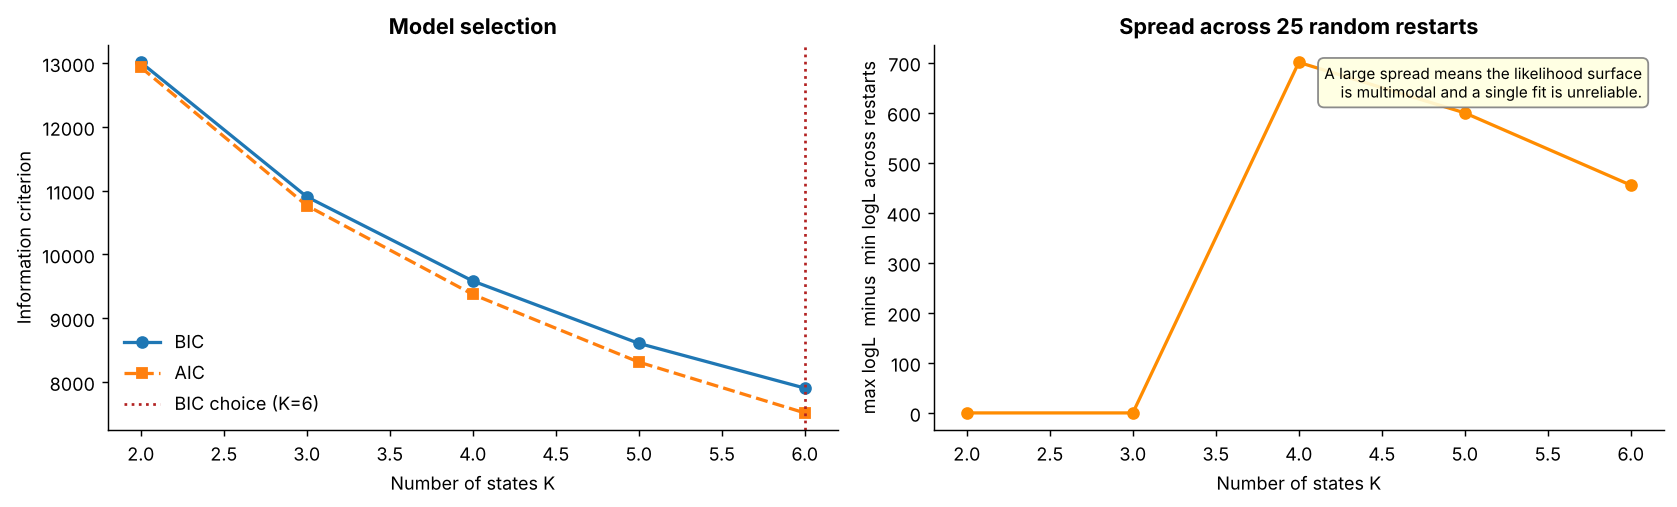

,log_lik,n_params,AIC,BIC,ll_spread,converged
K,,,,,,
2,-6454.62,13,12935.25,13013.11,0.00,True
3,-5360.65,23,10767.31,10905.08,0.00,True
4,-4652.12,35,9374.24,9583.89,700.53,True
5,-4107.29,49,8312.58,8606.08,599.52,True
6,-3692.70,65,7515.41,7904.75,455.13,True


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(selection.index, selection["BIC"], "o-", label="BIC", lw=1.8)
axes[0].plot(selection.index, selection["AIC"], "s--", label="AIC", lw=1.8)
axes[0].axvline(K_BIC, color="firebrick", ls=":", lw=1.5, label=f"BIC choice (K={K_BIC})")
axes[0].set_xlabel("Number of states K")
axes[0].set_ylabel("Information criterion")
axes[0].set_title("Model selection", fontweight="bold")
axes[0].legend(frameon=False)

axes[1].plot(selection.index, selection["ll_spread"], "o-", color="darkorange", lw=1.8)
axes[1].set_xlabel("Number of states K")
axes[1].set_ylabel("max logL  minus  min logL across restarts")
axes[1].set_title("Spread across 25 random restarts", fontweight="bold")
axes[1].text(0.97, 0.95,
             "A large spread means the likelihood surface\n"
             "is multimodal and a single fit is unreliable.",
             transform=axes[1].transAxes, ha="right", va="top", fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.4", fc="lightyellow", ec="grey", alpha=0.9))

plt.tight_layout()
plt.show()

display(selection.round(2))

### 4.2 Label switching

The likelihood is invariant under permutation of the state labels. Relabelling every state consistently gives an identical model with an identical likelihood, so "state 0" carries no meaning across restarts, across refits, or across any two runs of the code.

This is not pedantry. Any comparison between a model fitted on one window and a model fitted on another requires a deterministic ordering, or the comparison is between arbitrary labels. It is a routine source of silent errors in regime-switching work, particularly in rolling or walk-forward designs where the model is refitted repeatedly.

I impose an ordering by sorting states on mean realised volatility, ascending, so state 0 is always the calmest regime and the last state is the most volatile, which is the one treated as the stress state throughout.

The first version of this notebook sorted on mean return instead and called the lowest-return state the crisis state. With six states those two rankings disagreed: the lowest-return state ran at 21% volatility while a different state ran at 31%. Every crisis diagnostic downstream was therefore measuring the wrong state, the detection-lag table did not contain the COVID crash, and the regime strategy sat out days that went on to average a 28% annualised return. Nothing raised an error. The choice of sort key looked like housekeeping and was in fact the definition of the object the whole notebook is about.

In [17]:
K = 3            # fixed a priori, see section 4.1; BIC's choice is reported above as a diagnostic only
model = fitted[K]

# ── Resolve label switching ──────────────────────────────────────────────────
# The likelihood is invariant to permuting state labels, so "state 0" means
# nothing across restarts or across refits. Any downstream comparison requires
# a deterministic ordering. I sort by mean realised volatility in original
# units, ascending, so state 0 is always the calmest regime and state K-1 the
# most volatile. An earlier version sorted by mean return and called the
# lowest-return state the crisis state; with several states that is not the
# high-volatility one, and every crisis diagnostic downstream was wrong.

means_scaled = model.means_
means_orig = scaler.inverse_transform(means_scaled)
order = np.argsort(means_orig[:, 1])          # column 1 is realised volatility

# Rebuild the model's parameters under the new ordering
perm = np.empty(K, dtype=int)
perm[order] = np.arange(K)                     # old index -> new index

model_s = GaussianHMM(n_components=K, covariance_type="full")
model_s.startprob_ = model.startprob_[order]
model_s.transmat_ = model.transmat_[np.ix_(order, order)]
model_s.means_ = model.means_[order]
model_s.covars_ = model.covars_[order]
model_s.n_features = model.n_features

# ── Parameters in interpretable units ────────────────────────────────────────
means_o = scaler.inverse_transform(model_s.means_)
scale_vec = scaler.scale_
# Covariance in original units: S = diag(scale) * S_scaled * diag(scale)
covars_o = np.array([np.outer(scale_vec, scale_vec) * C for C in model_s.covars_])

state_table = pd.DataFrame({
    "mean daily return": means_o[:, 0],
    "ann. return": means_o[:, 0] * 252,
    "mean realised vol": means_o[:, 1],
    "ann. vol of returns": np.sqrt(covars_o[:, 0, 0] * 252),
}, index=[f"State {i}" for i in range(K)])

print("Fitted state parameters, original units\n")
print(state_table.to_string(float_format=lambda v: f"{v:8.4f}"))

Fitted state parameters, original units

         mean daily return  ann. return  mean realised vol  ann. vol of returns
State 0             0.0008       0.1909             0.1080               0.1113
State 1             0.0008       0.2070             0.1594               0.1620
State 2            -0.0003      -0.0701             0.2467               0.2591


### 4.3 Transition dynamics

Three quantities follow from the transition matrix, and together they say more about whether the model is useful than the log-likelihood does.

**Persistence** is the diagonal $a_{ii}$. For daily data, a regime worth the name should have $a_{ii}$ above roughly 0.95. Values near $1/K$ mean the chain is close to independent draws, which is to say there are no regimes, only a mixture.

**Expected duration** is $1/(1 - a_{ii})$, the mean of the geometric sojourn distribution. This converts the persistence into a number with units and makes the model's claim falsifiable: if the fitted crisis state has an expected duration of four days, it is detecting outliers rather than regimes.

**The stationary distribution** $\boldsymbol\pi^*$ solves $\boldsymbol\pi^* = \boldsymbol\pi^* A$, the left eigenvector of $A$ for eigenvalue 1. It gives the long-run share of time spent in each state, which is the right denominator when judging whether an estimated crisis state is plausible. A crisis regime occupying 40% of the sample is not a crisis regime.

In [18]:
A = model_s.transmat_

# Stationary distribution: the left eigenvector of A for eigenvalue 1,
# normalised to sum to one. This is the unconditional long-run share of time
# the chain spends in each state.
evals, evecs = np.linalg.eig(A.T)
stat = np.real(evecs[:, np.argmin(np.abs(evals - 1))])
stat = stat / stat.sum()

# Expected duration of a visit to state i. Because the sojourn time in a
# Markov chain is geometric with success probability (1 - a_ii), its mean is
# 1 / (1 - a_ii). This is a real restriction of the model rather than a
# convenience: the HMM cannot represent a regime whose hazard of ending
# changes with how long it has already lasted.
expected_duration = 1.0 / (1.0 - np.diag(A))

trans_df = pd.DataFrame(A,
                        index=[f"from S{i}" for i in range(K)],
                        columns=[f"to S{j}" for j in range(K)])

summary = pd.DataFrame({
    "persistence a_ii": np.diag(A),
    "expected duration (days)": expected_duration,
    "stationary share": stat,
}, index=[f"State {i}" for i in range(K)])

print("Transition matrix\n")
print(trans_df.to_string(float_format=lambda v: f"{v:7.4f}"))
print("\nImplied dynamics\n")
print(summary.to_string(float_format=lambda v: f"{v:9.4f}"))

Transition matrix

          to S0   to S1   to S2
from S0  0.9802  0.0190  0.0008
from S1  0.0202  0.9615  0.0183
from S2  0.0027  0.0280  0.9693

Implied dynamics

         persistence a_ii  expected duration (days)  stationary share
State 0            0.9802                   50.5411            0.4053
State 1            0.9615                   26.0043            0.3662
State 2            0.9693                   32.5214            0.2284


## 5. Filtered against smoothed, and why it decides whether any of this is usable

This is the section that matters. Everything else in the notebook is standard; this is where regime-switching work most often goes wrong, and the error is invisible in the output.

### Two different questions

The forward-backward algorithm produces the **smoothed** posterior

$$\gamma_t(i) = \Pr(S_t = i \mid \mathbf{x}_1, \dots, \mathbf{x}_T)$$

which conditions on the entire sample, including every observation after $t$. It answers: given everything I now know, what regime was the market in back then?

The forward recursion alone produces the **filtered** posterior

$$\hat{\alpha}_t(i) = \Pr(S_t = i \mid \mathbf{x}_1, \dots, \mathbf{x}_t)$$

which conditions only on data available at $t$. It answers: given what I knew at the time, what regime did I think I was in?

The first is a description of history. The second is a signal. They are not interchangeable, and the gap between them is exactly the value of hindsight.

### Why this trips people up

`hmmlearn`'s `predict_proba()` returns smoothed probabilities. `predict()` returns the Viterbi path, which also uses the full sample. Neither is available in real time, and neither function's name says so. The default path through the library therefore produces a beautiful regime chart that cannot be traded, and because the chart looks exactly like what a filtered chart would look like, nothing signals the problem.

The consequence is systematic. The smoothed path identifies the start of the 2020 and 2022 drawdowns almost exactly, because it has seen what followed. A backtest that allocates on that signal exits before the crash, every time, in every crash. The resulting equity curve is not merely optimistic, it is unachievable in principle, and it will look like skill rather than like a bug.

So I implement the forward recursion directly rather than using the library's posterior. The function below returns the filtered probabilities, the one-step-ahead predicted probabilities $\Pr(S_{t+1} \mid \mathbf{x}_{1:t})$, and the log-likelihood as a by-product.

### Scaling

Raw $\alpha$ values are products of densities and underflow to zero within a few hundred steps in double precision. The standard remedy is to normalise at each step by $c_t = \sum_i \alpha_t(i)$ and carry the normalised vector forward. This is convenient twice over: the normalised $\hat{\alpha}_t$ *is* the filtered posterior, and $\sum_t \ln c_t$ recovers the log-likelihood exactly. That second property gives a free correctness check, which the code uses: the hand-rolled recursion and `model.score()` should agree to machine precision, and if they do not, the implementation is wrong.

In [19]:
def forward_filter(X, model):
    """
    Scaled forward algorithm, returning genuinely filtered state probabilities.

    This is the function the whole notebook exists for, and it is not what
    hmmlearn gives you. `model.predict_proba(X)` runs forward-backward and
    returns SMOOTHED probabilities P(S_t | x_1 ... x_T), conditioned on the
    entire sample including everything after t. Those are the right quantity
    for describing history and completely wrong for any decision taken at t,
    because they embed information that did not exist yet.

    What a decision at time t can use is the filtered probability
    P(S_t | x_1 ... x_t), which the forward recursion alone produces:

        alpha_1(i)  = pi_i b_i(x_1)
        alpha_t(j)  = [ sum_i alpha_{t-1}(i) a_ij ] b_j(x_t)

    Raw alphas underflow to zero within a few hundred steps because they are
    products of densities, so each step is normalised by its sum c_t. The
    normalised alpha IS the filtered posterior, and sum(log c_t) recovers the
    log-likelihood, which gives a free correctness check against model.score().

    Returns
    -------
    filtered   : (T, K) P(S_t = i | x_1..x_t)
    predicted  : (T, K) P(S_{t+1} = i | x_1..x_t), the one-step-ahead forecast
    loglik     : float, should match model.score(X)
    """
    T_, K_ = X.shape[0], model.n_components
    A_ = model.transmat_
    pi_ = model.startprob_

    # Emission densities b_i(x_t) for every state and time
    B = np.empty((T_, K_))
    for i in range(K_):
        B[:, i] = multivariate_normal.pdf(X, mean=model.means_[i],
                                          cov=model.covars_[i],
                                          allow_singular=True)

    filtered = np.empty((T_, K_))
    predicted = np.empty((T_, K_))
    log_c = np.empty(T_)

    a = pi_ * B[0]
    c = a.sum()
    filtered[0] = a / c
    log_c[0] = np.log(c)

    for t in range(1, T_):
        pred = filtered[t - 1] @ A_          # P(S_t | x_1..x_{t-1})
        predicted[t - 1] = pred
        a = pred * B[t]
        c = a.sum()
        filtered[t] = a / c
        log_c[t] = np.log(c)

    predicted[T_ - 1] = filtered[T_ - 1] @ A_
    return filtered, predicted, log_c.sum()


filtered, predicted, ll_check = forward_filter(X, model_s)
smoothed = model_s.predict_proba(X)
viterbi = model_s.predict(X)

print(f"log-likelihood from forward recursion : {ll_check:,.4f}")
print(f"log-likelihood from hmmlearn score    : {model_s.score(X):,.4f}")
print(f"difference                            : {abs(ll_check - model_s.score(X)):.2e}")

# How much do the two disagree?
hard_filt = filtered.argmax(axis=1)
hard_smooth = smoothed.argmax(axis=1)
disagree = (hard_filt != hard_smooth)
print(f"\nDays where filtered and smoothed disagree on the state: "
      f"{disagree.sum():,} of {len(disagree):,}  ({disagree.mean():.1%})")
print(f"Days where filtered and Viterbi disagree               : "
      f"{(hard_filt != viterbi).sum():,}  ({(hard_filt != viterbi).mean():.1%})")

mean_abs_gap = np.abs(filtered - smoothed).max(axis=1).mean()
print(f"\nMean absolute gap in max-state probability: {mean_abs_gap:.4f}")

log-likelihood from forward recursion : -5,360.6545
log-likelihood from hmmlearn score    : -5,360.6545
difference                            : 4.09e-11

Days where filtered and smoothed disagree on the state: 163 of 2,951  (5.5%)
Days where filtered and Viterbi disagree               : 160  (5.4%)

Mean absolute gap in max-state probability: 0.0588


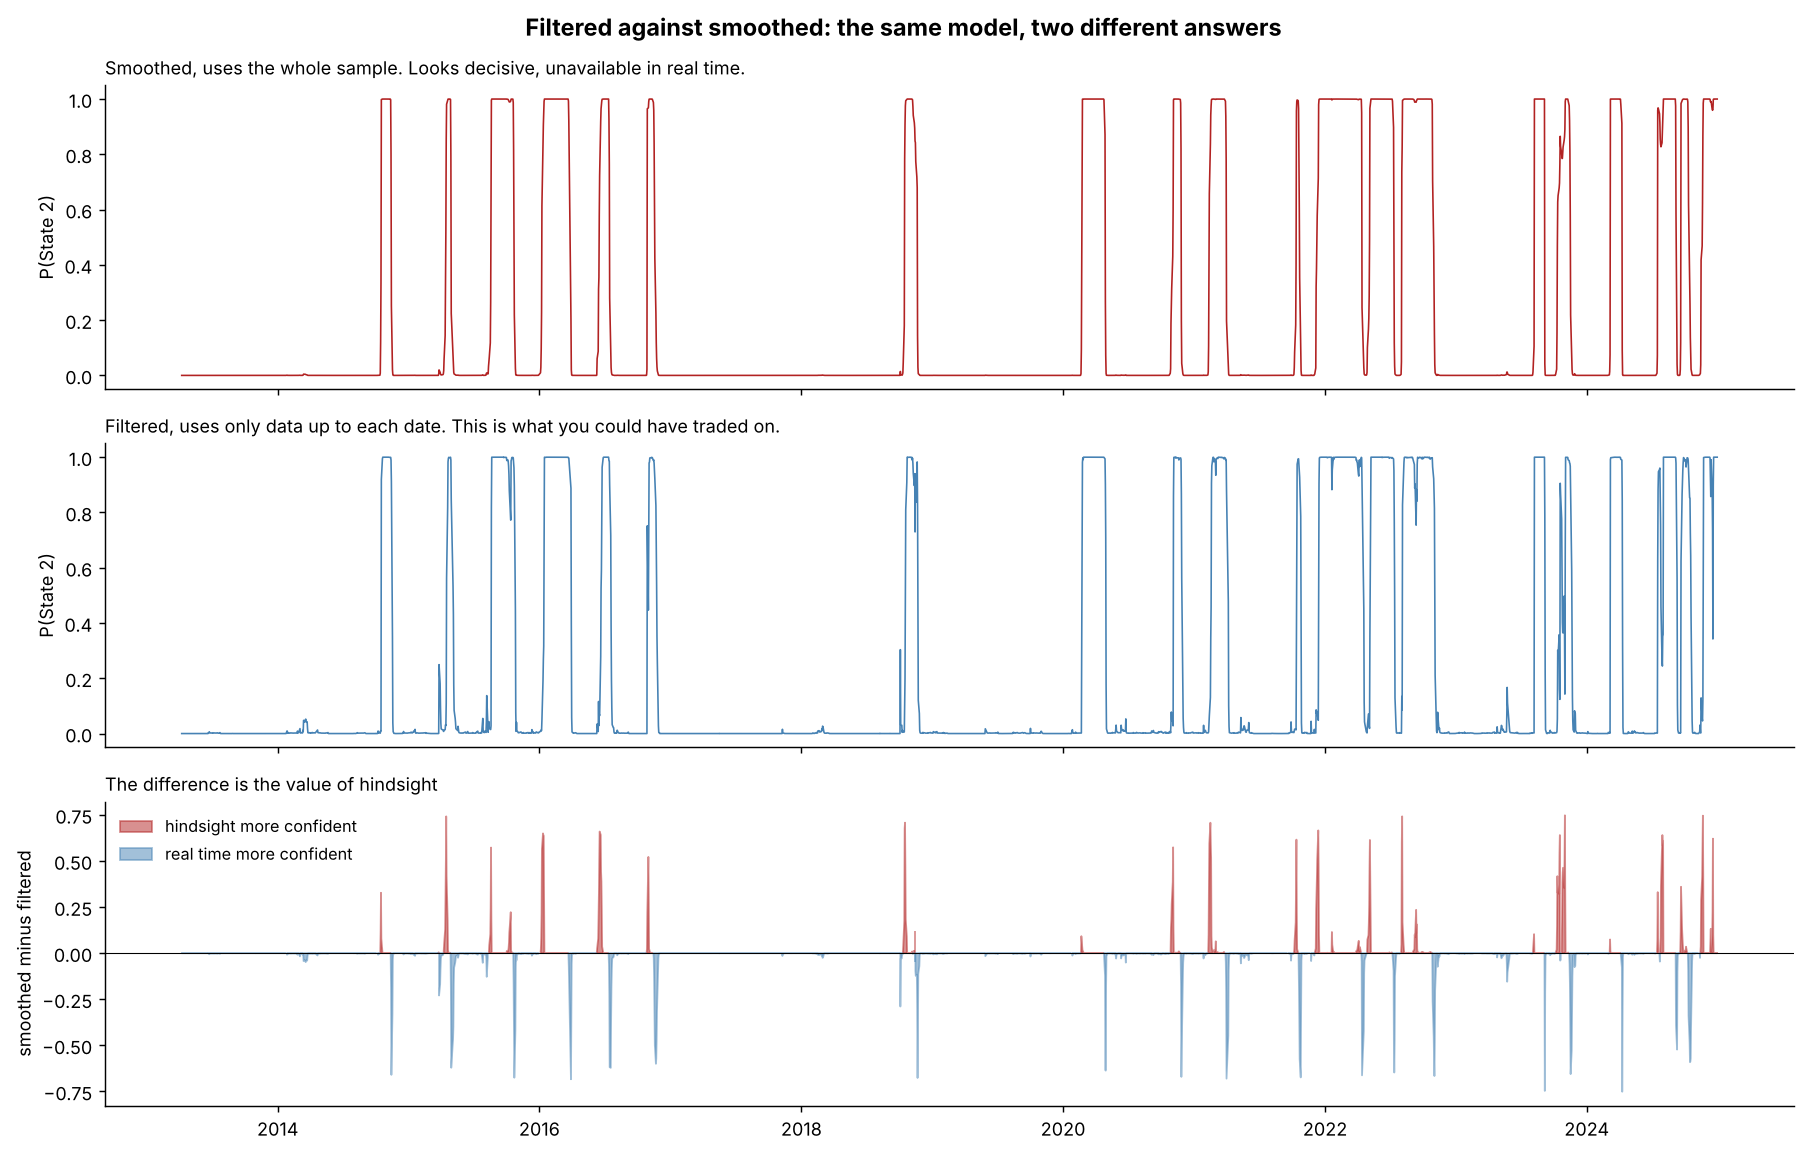

In [20]:
dates = features.index
crisis_state = K - 1      # highest mean realised volatility after relabelling

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig.suptitle("Filtered against smoothed: the same model, two different answers",
             fontsize=13, fontweight="bold")

axes[0].plot(dates, smoothed[:, crisis_state], lw=0.9, color="firebrick")
axes[0].set_ylabel(f"P(State {crisis_state})")
axes[0].set_title("Smoothed, uses the whole sample. Looks decisive, unavailable in real time.",
                  fontsize=10, loc="left")
axes[0].set_ylim(-0.05, 1.05)

axes[1].plot(dates, filtered[:, crisis_state], lw=0.9, color="steelblue")
axes[1].set_ylabel(f"P(State {crisis_state})")
axes[1].set_title("Filtered, uses only data up to each date. This is what you could have traded on.",
                  fontsize=10, loc="left")
axes[1].set_ylim(-0.05, 1.05)

gap = smoothed[:, crisis_state] - filtered[:, crisis_state]
axes[2].fill_between(dates, 0, gap, where=gap >= 0, color="firebrick", alpha=0.5,
                     label="hindsight more confident")
axes[2].fill_between(dates, 0, gap, where=gap < 0, color="steelblue", alpha=0.5,
                     label="real time more confident")
axes[2].axhline(0, color="black", lw=0.6)
axes[2].set_ylabel("smoothed minus filtered")
axes[2].set_title("The difference is the value of hindsight", fontsize=10, loc="left")
axes[2].legend(frameon=False, fontsize=9, loc="upper left")
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

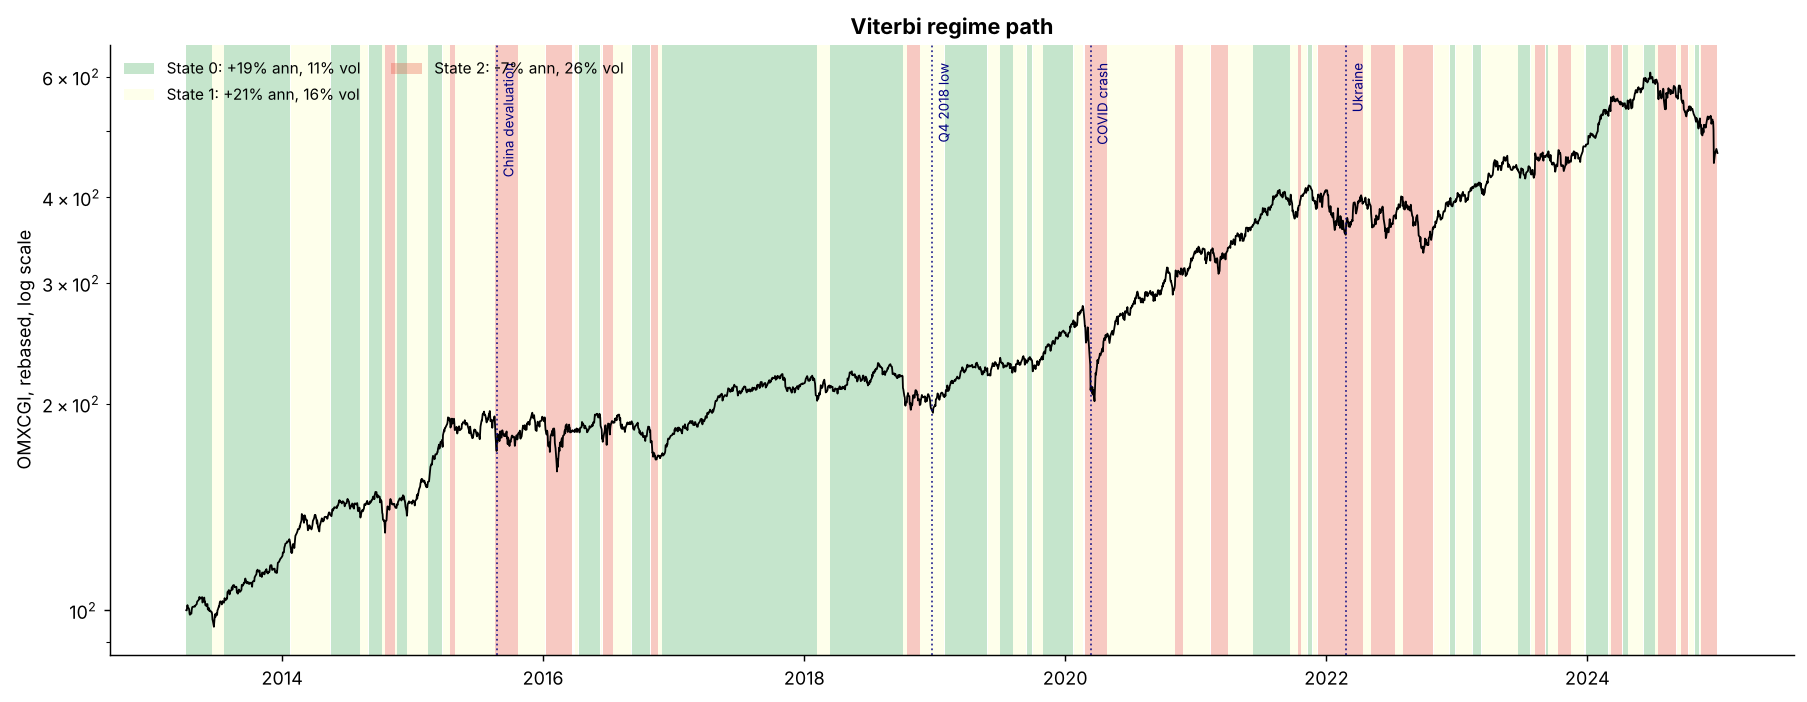

In [21]:
# Regime timeline with the Viterbi path shaded behind the price index
price = raw["OMXCGI Index"].reindex(dates).ffill()
rebased = price / price.iloc[0] * 100

palette = plt.cm.RdYlGn(np.linspace(0.85, 0.15, K))

fig, ax = plt.subplots(figsize=(14, 5.5))
for k in range(K):
    mask = viterbi == k
    ax.fill_between(dates, 0, 1, where=mask, transform=ax.get_xaxis_transform(),
                    color=palette[k], alpha=0.30, lw=0,
                    label=f"State {k}: {state_table['ann. return'].iloc[k]:+.0%} ann, "
                          f"{state_table['ann. vol of returns'].iloc[k]:.0%} vol")

ax.plot(dates, rebased, color="black", lw=1.0)
ax.set_yscale("log")
ax.set_ylabel("OMXCGI, rebased, log scale")
ax.set_title("Viterbi regime path", fontweight="bold")
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=2)

# Reference events. These are annotations, not inputs: the model never saw them.
events = {
    "2015-08-24": "China devaluation",
    "2018-12-24": "Q4 2018 low",
    "2020-03-12": "COVID crash",
    "2022-02-24": "Ukraine",
}
for d, label in events.items():
    d = pd.Timestamp(d)
    if dates[0] <= d <= dates[-1]:
        ax.axvline(d, color="navy", ls=":", lw=1.0, alpha=0.8)
        ax.annotate(label, xy=(d, ax.get_ylim()[1]), xytext=(2, -10),
                    textcoords="offset points", rotation=90,
                    fontsize=7.5, color="navy", va="top")

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 5.1 Detection lag

The comparison above is visual. This makes it a number.

For each episode that the smoothed path assigns to the crisis state, I find the first day on which the filtered probability of that state crossed one half. The difference is the detection lag: how long a real-time user sat inside a crisis before the model told them they were in one, and how much of the drawdown had already happened by then.

This is the single most useful diagnostic for deciding whether a regime model is worth building a strategy on. A model that identifies crises with a median lag of three days is a tool. One with a median lag of thirty days is a historian: correct, informative about the past, and useless for the decision it was built to inform, because by the time it fires the loss has been taken.

I expected this to be pessimistic, on the grounds that a single large negative return is consistent both with a crisis beginning and with an ordinary day in a fat-tailed distribution. It was not. The filtered probability crosses one half within zero to four trading days of the smoothed onset in every episode, and the COVID episode is flagged on the first day the smoothed path places it in the stress state.

That result needs reading carefully, because it is less impressive than it looks. The lag is measured against the smoothed path of the *same model*, so it shows how quickly real-time inference catches up with hindsight inference, not how quickly either catches up with the market. And the stress state is defined largely by the 21-day realised volatility, which itself trails price by construction: by the time trailing volatility is high enough to put the market in the stress state, the first leg of the selloff has usually already happened. A short lag here and an unchanged maximum drawdown in section 7 are consistent with each other for exactly that reason.

In [22]:
# How late is real time?
# For each contiguous episode the SMOOTHED path assigns to the crisis state,
# find the first day on which the FILTERED probability crossed 0.5. The gap is
# the detection lag: how many trading days a real-time user would have spent
# inside a crisis before the model told them they were in one.

smooth_hard = smoothed.argmax(axis=1)
in_crisis = smooth_hard == crisis_state

episodes = []
start = None
for i, flag in enumerate(in_crisis):
    if flag and start is None:
        start = i
    elif not flag and start is not None:
        if i - start >= 10:          # ignore episodes shorter than two weeks
            episodes.append((start, i - 1))
        start = None
if start is not None and len(in_crisis) - start >= 10:
    episodes.append((start, len(in_crisis) - 1))

rows = []
for s, e in episodes:
    crossed = np.where(filtered[s:e + 1, crisis_state] > 0.5)[0]
    lag = int(crossed[0]) if len(crossed) else np.nan
    seg_ret = features["log_return"].iloc[s:e + 1]
    rows.append({
        "start": dates[s].date(),
        "end": dates[e].date(),
        "length (days)": e - s + 1,
        "detection lag (days)": lag,
        "drawdown during lag": (np.exp(seg_ret.iloc[:lag].sum()) - 1) if lag and lag > 0 else 0.0,
        "total episode return": np.exp(seg_ret.sum()) - 1,
    })

lag_table = pd.DataFrame(rows)
print("Crisis episodes identified with hindsight, and how long real time took to see them\n")
print(lag_table.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))

valid = lag_table["detection lag (days)"].dropna()
if len(valid):
    print(f"\nMedian detection lag : {valid.median():.0f} trading days")
    print(f"Mean loss incurred before the signal fires: "
          f"{lag_table['drawdown during lag'].mean():.2%}")

Crisis episodes identified with hindsight, and how long real time took to see them

     start        end  length (days)  detection lag (days)  drawdown during lag  total episode return
2014-10-17 2014-11-13             20                     0                0.000                 0.091
2015-04-15 2015-04-29             11                     2               -0.006                -0.032
2015-08-19 2015-10-22             47                     1               -0.012                -0.071
2016-01-08 2016-03-23             54                     4               -0.020                -0.016
2016-06-16 2016-07-14             21                     3                0.010                 0.156
2016-10-28 2016-11-17             15                     0                0.000                -0.081
2018-10-16 2018-11-20             26                     2                0.023                -0.009
2020-02-24 2020-04-27             44                     0                0.000                -0.08

## 6. Out-of-sample

Filtering fixes the timing of the *data*. It does not fix the timing of the *parameters*.

Every result above fits the model on the full sample and then filters through it. The filtered probabilities are honest about which observations they condition on, but the transition matrix, the state means and the state covariances were all estimated with knowledge of the entire history, including the holdout. A real-time user in 2019 would not have had those parameters, because they were partly determined by what happened in 2020.

This section removes that advantage. The model is refitted on data to the end of 2018 only, the parameters are frozen, and the filter is then run forward through the remaining decade. That is the one configuration an actual user could have operated.

Two things are worth watching.

**Do the states survive?** If the regimes fitted on 2013 to 2018, a window whose worst episodes are the 2015 devaluation scare and the end of 2018, still describe 2019 to 2024, a window containing a pandemic and an inflation shock, then the model has found something structural. If the fitted means and persistences differ sharply from the full-sample ones, it has fitted a period.

**Does the state carry information about the future?** The table below conditions next-day outcomes on the previous day's filtered state. The one-day lag is not optional: the state probability at time $t$ is computed from the close at $t$, so the earliest it can be acted on is $t+1$.

The expectation here was asymmetric: regime models identify volatility states more reliably than return states, because volatility is persistent and forecastable while returns are close to unforecastable. That is what happened. Out of sample, the day after a filtered stress-state reading had annualised volatility of 22.6% against 13.6% after a calm reading, a gap that held up from a model fitted only on 2013 to 2018. The return ordering was weaker and not monotone, with the middle state outperforming the calm one. The model is a usable volatility classifier and a doubtful return forecaster, which points its application toward risk management rather than directional timing.

The training window is short, under six years, and contains no crisis comparable to what follows it. That is a hard test: the model has to recognise a pandemic crash using states estimated on milder stress. It is also the test a real user in 2019 would have faced.

In [23]:
# ── Genuine out-of-sample test ───────────────────────────────────────────────
# Everything above fits on the full sample. Even the filtered probabilities,
# honest as they are about the TIMING of information, use parameters estimated
# with knowledge of the whole series. A real-time user would not have had those
# parameters either.
#
# This block refits on the first part of the sample only, then filters forward
# through the holdout using the frozen parameters. That is the one configuration
# an actual user could have run.

SPLIT_DATE = "2019-01-01"
split_idx = features.index.searchsorted(pd.Timestamp(SPLIT_DATE))

X_train, X_test = X[:split_idx], X[split_idx:]
print(f"Train : {dates[0].date()} to {dates[split_idx-1].date()}  ({split_idx:,} days)")
print(f"Test  : {dates[split_idx].date()} to {dates[-1].date()}  ({len(X_test):,} days)")

model_tr, ll_tr, _ = fit_hmm(X_train, K, n_restarts=25)

# Relabel the training model on the same convention
means_tr = scaler.inverse_transform(model_tr.means_)
order_tr = np.argsort(means_tr[:, 1])
model_tr_s = GaussianHMM(n_components=K, covariance_type="full")
model_tr_s.startprob_ = model_tr.startprob_[order_tr]
model_tr_s.transmat_ = model_tr.transmat_[np.ix_(order_tr, order_tr)]
model_tr_s.means_ = model_tr.means_[order_tr]
model_tr_s.covars_ = model_tr.covars_[order_tr]
model_tr_s.n_features = model_tr.n_features

# Filter through the FULL series with frozen parameters, then keep the test part.
# Filtering the whole series is correct: the recursion at time t depends only on
# data up to t, so running it from the start simply gives the test period a
# properly initialised state distribution rather than an arbitrary prior.
filt_oos_full, pred_oos_full, _ = forward_filter(X, model_tr_s)
filt_oos = filt_oos_full[split_idx:]

print("\nTrain-period parameters, original units\n")
tr_means = scaler.inverse_transform(model_tr_s.means_)
tr_tbl = pd.DataFrame({
    "ann. return": tr_means[:, 0] * 252,
    "mean realised vol": tr_means[:, 1],
    "persistence": np.diag(model_tr_s.transmat_),
}, index=[f"State {i}" for i in range(K)])
print(tr_tbl.to_string(float_format=lambda v: f"{v:8.4f}"))

# Does the out-of-sample state assignment carry information about future risk?
test_ret = features["log_return"].iloc[split_idx:]
oos_state = filt_oos.argmax(axis=1)
grp = pd.DataFrame({"state": oos_state, "ret": test_ret.values}, index=test_ret.index)
# Shift by one day: act on yesterday's filtered state, measure today's outcome
grp["state_lag"] = grp["state"].shift(1)
oos_summary = grp.dropna().groupby("state_lag")["ret"].agg(
    days="size",
    ann_return=lambda s: s.mean() * 252,
    ann_vol=lambda s: s.std() * np.sqrt(252),
)
print("\nOut-of-sample: next-day outcomes conditional on yesterday's filtered state\n")
print(oos_summary.to_string(float_format=lambda v: f"{v:9.4f}"))

Train : 2013-04-08 to 2018-12-28  (1,434 days)
Test  : 2019-01-02 to 2024-12-30  (1,517 days)


Model is not converging.  Current: -2174.4768329088647 is not greater than -2174.4768323457624. Delta is -5.631022759189364e-07


Model is not converging.  Current: -2257.2735954499262 is not greater than -2257.273593515243. Delta is -1.9346830413269345e-06


Model is not converging.  Current: -2174.4768328236096 is not greater than -2174.476832336198. Delta is -4.87411398353288e-07


Model is not converging.  Current: -2257.273576471291 is not greater than -2257.2735719971374. Delta is -4.474153683986515e-06


Model is not converging.  Current: -2174.4768329093145 is not greater than -2174.4768323219814. Delta is -5.873330337635707e-07



Train-period parameters, original units

         ann. return  mean realised vol  persistence
State 0       0.1930             0.1049       0.9876
State 1       0.1080             0.1631       0.9649
State 2       0.0679             0.2594       0.9582

Out-of-sample: next-day outcomes conditional on yesterday's filtered state

           days  ann_return   ann_vol
state_lag                            
0.0         401      0.1348    0.1358
1.0         711      0.1768    0.1879
2.0         404      0.0339    0.2264


## 7. A regime-conditional allocation

The test of a regime model is not whether the chart looks convincing. It is whether a decision rule built on it survives honest accounting.

Four constraints, each of which costs performance and each of which is required:

1. **Filtered probabilities only.** Never smoothed, never Viterbi.
2. **Training-period parameters only.** Frozen at the end of 2018.
3. **One-day lag.** A state inferred from today's close is actionable tomorrow at the earliest.
4. **Transaction costs** on every change in exposure, at 10 bps.

The rule itself is deliberately trivial: hold the index when the filtered probability of the crisis state is below one half, hold cash otherwise. I kept it to a single threshold with no free parameters beyond the obvious one, because the question is whether the regime signal contains information, and a more elaborate rule would make it impossible to tell whether any result came from the signal or from the rule.

### The counterfactual

Alongside the honest version I run the identical rule on smoothed probabilities. That version requires seeing the future and cannot be implemented by anyone. It is included precisely because it is the number that gets published by accident, and seeing the two curves on one axis is the clearest possible argument for why the distinction in section 5 is not a technicality.

### What it produced

| 2019 to 2024, net of costs | Buy and hold | Filtered, lagged | Smoothed (not implementable) |
|---|---|---|---|
| Annualised return | 13.8% | 12.2% | 18.8% |
| Annualised volatility | 18.7% | 14.6% | |
| Sharpe ratio | 0.74 | 0.84 | 1.39 |
| Maximum drawdown | -27.4% | -28.0% | -15.2% |

The honest version is a de-risking overlay, not a crash avoider. It spent about 27% of the period in cash, cut volatility by four points, gave up 1.6 points of return, and did not reduce the maximum drawdown at all. The Sharpe ratio improvement of 0.10 over six years is far inside sampling noise, since the standard error of a Sharpe ratio estimated over six years is around 0.4. Thirty-one changes of exposure cost 3.1% of capital.

The smoothed version is what the same rule looks like when it can see the future: nearly half the drawdown and a Sharpe ratio of 1.39. The distance between those two columns is the value of hindsight, and a regime-switching backtest that does not say which posterior it traded on could be reporting either one.

In [24]:
# ── A regime-conditional allocation, built to be honest ──────────────────────
# Rules:
#   1. Only FILTERED probabilities are used, never smoothed and never Viterbi.
#   2. Parameters come from the training period only.
#   3. The signal is lagged one day. The state probability computed from
#      today's close can only be acted on at tomorrow's open at the earliest.
#   4. Transaction costs are charged on every change in exposure.
#
# Dropping any one of these produces a dramatically better backtest and a
# meaningless one.

COST_BPS = 10.0

p_crisis = filt_oos[:, crisis_state]
raw_exposure = np.where(p_crisis > 0.5, 0.0, 1.0)

exposure = pd.Series(raw_exposure, index=test_ret.index).shift(1).fillna(1.0)
turnover = exposure.diff().abs().fillna(0.0)

simple_ret = np.exp(test_ret) - 1
strategy_ret = exposure * simple_ret - turnover * COST_BPS / 10_000
buyhold_ret = simple_ret


def perf(r, name):
    ann_ret = (1 + r).prod() ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol if ann_vol > 0 else np.nan
    curve = (1 + r).cumprod()
    dd = (curve / curve.cummax() - 1).min()
    return {"strategy": name, "ann. return": ann_ret, "ann. vol": ann_vol,
            "Sharpe": sharpe, "max drawdown": dd,
            "time invested": exposure.mean() if name != "Buy and hold" else 1.0}


results = pd.DataFrame([
    perf(buyhold_ret, "Buy and hold"),
    perf(strategy_ret, "Regime switch, filtered"),
]).set_index("strategy")

print(f"Out-of-sample, {test_ret.index[0].date()} to {test_ret.index[-1].date()}, "
      f"{COST_BPS:.0f} bps per unit of turnover\n")
print(results.to_string(float_format=lambda v: f"{v:9.4f}"))
print(f"\nNumber of exposure changes: {int((turnover > 0).sum())}")
print(f"Total cost paid           : {(turnover * COST_BPS / 10_000).sum():.4f} "
      f"({(turnover * COST_BPS / 10_000).sum():.2%} of capital)")

# The counterfactual that shows why the distinction matters
smooth_oos = model_tr_s.predict_proba(X)[split_idx:]
cheat_exposure = pd.Series(np.where(smooth_oos[:, crisis_state] > 0.5, 0.0, 1.0),
                           index=test_ret.index).shift(1).fillna(1.0)
cheat_turnover = cheat_exposure.diff().abs().fillna(0.0)
cheat_ret = cheat_exposure * simple_ret - cheat_turnover * COST_BPS / 10_000
cheat = perf(cheat_ret, "Regime switch, smoothed")
print(f"\nSame rule run on SMOOTHED probabilities, which require seeing the future:")
print(f"  ann. return {cheat['ann. return']:.4f}   Sharpe {cheat['Sharpe']:.4f}   "
      f"max drawdown {cheat['max drawdown']:.4f}")
print(f"  This is the number that gets published by accident.")

Out-of-sample, 2019-01-02 to 2024-12-30, 10 bps per unit of turnover

                         ann. return  ann. vol    Sharpe  max drawdown  time invested
strategy                                                                             
Buy and hold                  0.1380    0.1865    0.7399       -0.2737         1.0000
Regime switch, filtered       0.1220    0.1459    0.8360       -0.2796         0.7337

Number of exposure changes: 31
Total cost paid           : 0.0310 (3.10% of capital)

Same rule run on SMOOTHED probabilities, which require seeing the future:
  ann. return 0.1877   Sharpe 1.3909   max drawdown -0.1515
  This is the number that gets published by accident.


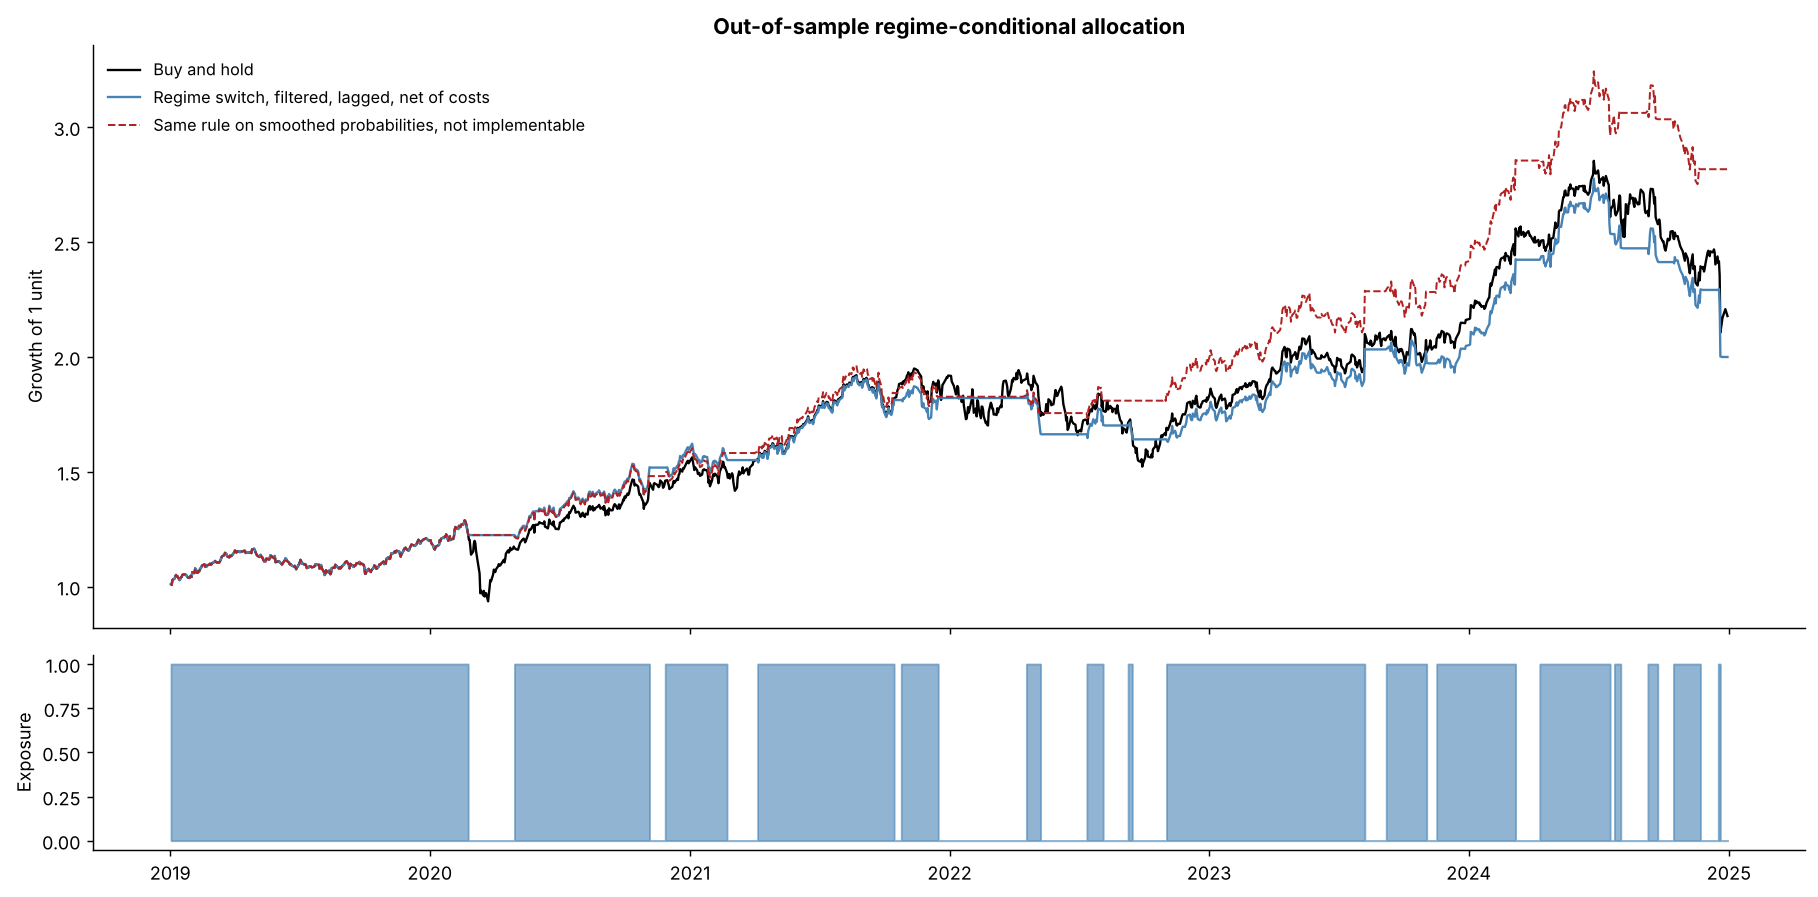

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

axes[0].plot(test_ret.index, (1 + buyhold_ret).cumprod(), lw=1.3,
             color="black", label="Buy and hold")
axes[0].plot(test_ret.index, (1 + strategy_ret).cumprod(), lw=1.3,
             color="steelblue", label="Regime switch, filtered, lagged, net of costs")
axes[0].plot(test_ret.index, (1 + cheat_ret).cumprod(), lw=1.1, ls="--",
             color="firebrick", label="Same rule on smoothed probabilities, not implementable")
axes[0].set_ylabel("Growth of 1 unit")
axes[0].set_title("Out-of-sample regime-conditional allocation", fontweight="bold")
axes[0].legend(frameon=False, fontsize=9)

axes[1].fill_between(test_ret.index, 0, exposure.values, step="pre",
                     color="steelblue", alpha=0.6)
axes[1].set_ylabel("Exposure")
axes[1].set_ylim(-0.05, 1.05)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

## 8. Limitations

Stated here rather than in an appendix, because several of them bear directly on how much weight the preceding results can carry.

**Gaussian emissions are probably not enough.** The mixture is fat-tailed unconditionally, which was the point, but a Gaussian within each regime still understates the tails inside a crisis state. A Student-$t$ emission density is the natural extension and adds one degrees-of-freedom parameter per state.

**Geometric sojourn times.** The Markov assumption forces a constant hazard of leaving a regime, so the model cannot express the idea that a crisis which has already lasted six months is more, or less, likely to end soon. Hidden semi-Markov models allow an explicit duration distribution. Whether the added parameters earn their keep on 5,000 observations is doubtful.

**$K$ is chosen, not estimated.** BIC selects among a candidate set that I specified. The penalised-likelihood framework assumes the true model is in that set, which it is not. The selected $K$ should be read as the most useful description available, not as a discovery about how many regimes exist.

**Realised volatility is backward looking by 21 days.** The second observable is a trailing window, which means part of the detection lag measured in section 5.1 is mechanical: the feature itself cannot respond to a shock faster than its own window. Shortening the window trades responsiveness for noise, and the choice of 21 days was made on convention rather than on evidence. A model using high-frequency realised variance, or an EWMA with a shorter effective memory, would be more responsive and is the obvious next experiment.

**Single market, single sample.** One index, one country, one window of under twelve years, and no slow-moving financial crisis in it: the crisis state is estimated mostly from the COVID crash. Nothing here has been tested for robustness across markets, and Danish equities are a small and concentrated market in which one issuer dominates the index. The Novo Nordisk weight alone means the benchmark is closer to a single-name proxy than a diversified index for much of the later sample.

**Two configurations, one split.** Section 7 runs one rule with one threshold, but on the second model specification tried: the six-state model came first and is disclosed in section 4.1. I have not searched over thresholds or lookbacks. The result rests on a single train/test split of six years each, and the Sharpe ratio difference it produces is well within noise. The broader problem, that performance figures need correcting for the search that produced them, is the subject of separate work.

## What I would do next

Student-$t$ emissions, to stop the crisis state understating its own tail.

A shorter-memory volatility observable, to separate mechanical detection lag from genuine inference lag.

Replication across several European indices, since a regime structure that appears only in Denmark is more likely a property of this sample than of markets.

Comparison against a Markov-switching GARCH specification, which models the volatility process inside each regime rather than treating realised volatility as an observation, and against a simple threshold rule on trailing volatility, which is the baseline this whole apparatus has to beat.